# Reviewer-response studies

## Study 1: are $N_\mathrm{res}$ and $N_\mathrm{unres}$ approximately Poisson?

PELARGIR (Criswell et al., [arXiv:2604.03390](https://arxiv.org/abs/2604.03390)) treats the number of resolved
Galactic binaries as Poisson: Appendix A, Eqs. (A2) and (A5), give $p(N_\mathrm{res}\,|\,\lambda) = \mathrm{Poisson}(\lambda)$.
Appendix B states that the total number of unresolved binaries is also a Poisson process, then works with a
Gaussian limit of it (footnote 8).

Each simulated galaxy, however, draws a **fixed** total $N_\mathrm{tot}$ of binaries, so the in-band count is
strictly $\mathrm{Binomial}(N_\mathrm{tot}, p_\mathrm{band})$. $N_\mathrm{res}$ then passes through the per-bin
SNR thresholding of Eqs. (14)–(19), with the boundary estimator of Eq. (17). This notebook measures how close
the resulting count distributions are to Poisson.

**Setup**
- Use three points in population space: the Table 1 simulated values, plus two draws from the Table 1 hyperprior.
- Use a band of 10 frequency bins of width $\Delta f = 10^{-5}$ Hz centred on 1 mHz (0.95–1.05 mHz).
- Draw 1000 galaxy realizations per point, each with $N_\mathrm{tot} = 10^7$ binaries and $\rho_\mathrm{thresh} = 7$.
- For each realization, sum the band totals $N_\mathrm{res}$ and $N_\mathrm{unres} = N_\mathrm{in\,band} - N_\mathrm{res}$.
- Fit a Poisson distribution to each set of counts ($\hat\lambda$ = sample mean, the MLE). Report a binned
  KL divergence $D_\mathrm{KL}(\hat p\,\|\,\mathrm{Poisson}(\hat\lambda))$, calibrated against a parametric-bootstrap
  Poisson null, and the dispersion index $D = s^2/\bar x$.

The notebook uses the `main`-branch code with cupy on the GPU (`PELARGIR_GPU=1`) and runs in the `gwenv-1` kernel.

The simulated counts are saved at the end of the simulation section. **Further analyses and figure edits can
start from the "Load data" cell** in a fresh kernel, without pelargir or a GPU.

## Statistics helpers

These helpers are used by every study below. **Run both helper cells first** when restarting from any
"Load data" cell. They need only numpy, scipy, pandas and matplotlib.
- The first cell holds the Poisson tests. The method is described under Study 1 → Statistics.
- The second holds the full-band loading, summary and plotting functions shared by Studies 1b–1d and the symmetry check.

In [1]:
import numpy as np
import scipy.stats as ss


def binned_poisson_kl(samples, n_bins=30):
    '''

    KL divergence of the binned empirical distribution of integer samples from a Poisson fit (lambda = mean).

    Arguments
    ------------------------------
    samples : numpy.ndarray
    	Integer counts, shape (n,).
    n_bins : int
    	Target number of equal-width, integer-aligned bins spanning [min, max] of the samples. (Default: 30)

    Returns
    ------------------------------
    kl : float
    	D_KL(p_hat || q) in nats, summed over bins with p_hat > 0.
    edges : numpy.ndarray
    	Bin edges at half-integers, shape (n_bins_used + 1,); the outer bins carry the Poisson tails.
    p_hat : numpy.ndarray
    	Empirical fraction of samples per bin.
    q : numpy.ndarray
    	Poisson(lambda_hat) probability mass per bin (sums to 1).
    lam : float
    	Fitted Poisson rate (sample mean).

    '''
    lam = samples.mean()
    lo, hi = samples.min(), samples.max()
    width = max(1, int(np.ceil((hi - lo + 1)/n_bins)))
    nb = int(np.ceil((hi - lo + 1)/width))
    ## bin k holds the integers lo + width*k ... lo + width*(k+1) - 1
    edges = lo - 0.5 + width*np.arange(nb + 1)
    p_hat = np.histogram(samples, bins=edges)[0]/len(samples)
    ## Poisson mass per bin from CDF differences, with the outer bins extended to -inf / +inf
    cdf = ss.poisson.cdf(np.floor(edges), lam)
    cdf[0], cdf[-1] = 0.0, 1.0
    q = np.diff(cdf)
    keep = p_hat > 0
    kl = np.sum(p_hat[keep]*np.log(p_hat[keep]/q[keep]))
    return kl, edges, p_hat, q, lam


def poisson_null_kl(lam, n, n_boot=1000, n_bins=30, rng=None):
    '''

    Parametric-bootstrap null distribution of binned_poisson_kl for n genuine Poisson(lam) samples, each
    replicate refit and rebinned by the same rule as the data.

    Arguments
    ------------------------------
    lam : float
    	Poisson rate to draw the null samples from (the fit to the data).
    n : int
    	Samples per replicate (the number of realizations).
    n_boot : int
    	Number of bootstrap replicates. (Default: 1000)
    n_bins : int
    	Passed to binned_poisson_kl. (Default: 30)
    rng : numpy.random.Generator or None
    	Random generator. (Default: None, a fresh default_rng())

    Returns
    ------------------------------
    kl_null : numpy.ndarray
    	Null KL values, shape (n_boot,).

    '''
    rng = np.random.default_rng() if rng is None else rng
    draws = rng.poisson(lam, size=(n_boot, n))
    return np.array([binned_poisson_kl(d, n_bins)[0] for d in draws])


def dispersion_index(samples):
    '''

    Dispersion index s^2/mean and its two-sided p-value under the Poisson null, (n-1) D ~ chi^2_{n-1}.

    Arguments
    ------------------------------
    samples : numpy.ndarray
    	Integer counts, shape (n,).

    Returns
    ------------------------------
    D : float
    	Dispersion index (sample variance with ddof=1, over the sample mean).
    p_D : float
    	Two-sided p-value of D under the Poisson null.

    '''
    n = len(samples)
    D = samples.var(ddof=1)/samples.mean()
    cdf = ss.chi2.cdf((n - 1)*D, n - 1)
    return D, 2*min(cdf, 1 - cdf)

In [2]:
import os
import numpy as np
import scipy.stats as ss
import pandas as pd
import matplotlib.pyplot as plt

FB_LABELS = {'N_res': r'$N_\mathrm{res}$', 'N_unres': r'$N_\mathrm{unres}$', 'N_in': r'$N_\mathrm{in}$'}


def load_fullband(path, subband_width):
    '''

    Load a full-band per-bin count file (Studies 1b and 1c) and aggregate it into full-band totals and
    sub-bands.

    Arguments
    ------------------------------
    path : str
    	npz file written by a full-band simulation cell (per-bin N_res_f and N_in_f of shape (nreal, nbins)).
    subband_width : float
    	Sub-band width [Hz]; must be a whole number of bins. Bins left over at the top of the band are dropped.

    Returns
    ------------------------------
    data : dict
    	'meta' (all npz arrays), 'nreal', 'n_sub', 'subband_width', 'sub_lo' and 'sub_centres' [Hz];
    	'full' and 'sub' count dicts {'N_res', 'N_unres', 'N_in'} of shapes (nreal,) and (nreal, n_sub);
    	'D_ref_full' and 'D_ref_sub', the expected dispersion index of the in-band count with no
    	thresholding: binomial 1 - p for fixed N_tot, exactly 1 for Poisson N_tot (files with 'lambda_tot').

    '''
    with np.load(path) as f:
        meta = {k: f[k] for k in f.files}
    nres, nin = meta['N_res_f'], meta['N_in_f']
    nreal, nbins = nres.shape
    bins_per_sub = int(round(subband_width/meta['fbin']))
    n_sub = nbins//bins_per_sub
    per_bin = {'N_res': nres, 'N_unres': nin - nres, 'N_in': nin}
    full = {q: x.sum(axis=1) for q, x in per_bin.items()}
    ## group consecutive bins into sub-bands: shape (nreal, n_sub)
    sub = {q: x[:, :n_sub*bins_per_sub].reshape(nreal, n_sub, bins_per_sub).sum(axis=2) for q, x in per_bin.items()}
    if 'lambda_tot' in meta:
        ## Poisson N_tot: the in-band count is a Poisson thinning, so exactly Poisson
        D_ref_full, D_ref_sub = 1.0, np.ones(n_sub)
    else:
        ## fixed N_tot: the in-band count is Binomial(N_tot, p), D = 1 - p
        D_ref_full = 1 - full['N_in'].mean()/meta['ntot']
        D_ref_sub = 1 - sub['N_in'].mean(axis=0)/meta['ntot']
    sub_lo = meta['fmin'] + subband_width*np.arange(n_sub)
    return {'meta': meta, 'nreal': nreal, 'n_sub': n_sub, 'subband_width': subband_width, 'sub_lo': sub_lo,
            'sub_centres': sub_lo + subband_width/2, 'full': full, 'sub': sub,
            'D_ref_full': D_ref_full, 'D_ref_sub': D_ref_sub}


def poisson_tests(x, rng):
    '''

    Binned-KL bootstrap test and dispersion-index test of one set of counts against Poisson(mean).

    Arguments
    ------------------------------
    x : numpy.ndarray
    	Integer counts across realizations, shape (n,).
    rng : numpy.random.Generator
    	Random generator for the bootstrap null.

    Returns
    ------------------------------
    res : dict
    	lambda_hat, sample var, D, p_D, D_KL, null median / 95%, p_KL, and the KL edges/null for plotting.

    '''
    kl, edges, p_hat, q, lam = binned_poisson_kl(x)
    kl_null = poisson_null_kl(lam, len(x), rng=rng)
    D, p_D = dispersion_index(x)
    return {'lambda_hat': lam, 'sample var': x.var(ddof=1), 'D = var/mean': D, 'p_D': p_D, 'D_KL [nats]': kl,
            'null median': np.median(kl_null), 'null 95%': np.percentile(kl_null, 95),
            'p_KL': np.mean(kl_null >= kl), '_edges': edges, '_kl_null': kl_null}


def fullband_poisson_summary(data, rng):
    '''

    Run poisson_tests on N_res and N_unres for the full band and every sub-band, print how often each test
    rejects at 5% across sub-bands, and tabulate the results.

    Arguments
    ------------------------------
    data : dict
    	Output of load_fullband.
    rng : numpy.random.Generator
    	Random generator for the bootstrap nulls (consumed in a fixed order, so results are reproducible).

    Returns
    ------------------------------
    results : dict
    	{(band label, quantity): poisson_tests output}, including the KL edges and null for plotting.
    summary : pandas.DataFrame
    	One row per (band, quantity), with the poisson_tests statistics and D_ref(N_in), the no-thresholding
    	expectation for the in-band count's dispersion.

    '''
    w = data['subband_width']
    bands = [('full band', None)] + [(f"{lo*1e3:.1f}-{(lo + w)*1e3:.1f} mHz", j) for j, lo in enumerate(data['sub_lo'])]
    results = {}
    for qname in ['N_res', 'N_unres']:
        for label, j in bands:
            x = data['full'][qname] if j is None else data['sub'][qname][:, j]
            results[(label, qname)] = poisson_tests(x, rng)
            results[(label, qname)]['D_ref(N_in)'] = data['D_ref_full'] if j is None else data['D_ref_sub'][j]
    summary = pd.DataFrame({k: {c: v for c, v in r.items() if not c.startswith('_')} for k, r in results.items()}).T
    summary.index.names = ['band', 'quantity']
    summary = summary.astype(float)
    ## sub-band overview: how often each test rejects at 5%, against the ~5% expected by chance
    for qname in ['N_res', 'N_unres']:
        s = summary.xs(qname, level='quantity').drop('full band')
        print(f"{qname:>8}: {len(s)} sub-bands; median D = {s['D = var/mean'].median():.3f} "
              f"(range {s['D = var/mean'].min():.3f}-{s['D = var/mean'].max():.3f}); "
              f"p_D < 0.05 in {np.sum(s['p_D'] < 0.05)}, p_KL < 0.05 in {np.sum(s['p_KL'] < 0.05)} "
              f"(expected by chance: {0.05*len(s):.1f})")
    return results, summary


def plot_fullband_hist(data, results, title, outfile):
    '''

    Histograms of the full-band N_res and N_unres with the fitted Poisson pmf and the test statistics.

    Arguments
    ------------------------------
    data : dict
    	Output of load_fullband.
    results : dict
    	Output of fullband_poisson_summary.
    title : str
    	Figure title.
    outfile : str
    	PNG path to save to.

    Returns
    ------------------------------
    fig : matplotlib.figure.Figure
    	The figure.

    '''
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    f_lo, f_hi = data['meta']['fmin']*1e3, data['meta']['fmax']*1e3
    for ax, qname in zip(axes, ['N_res', 'N_unres']):
        r = results[('full band', qname)]
        x = data['full'][qname]
        lam, edges = r['lambda_hat'], r['_edges']
        width = edges[1] - edges[0]
        ## empirical density per unit count on the KL bins, against the fitted Poisson pmf
        h = ax.hist(x, bins=edges, density=True, color='C0', alpha=0.6, label='realizations')[0]
        k = np.arange(int(np.floor(lam - 5*np.sqrt(lam))), int(np.ceil(lam + 5*np.sqrt(lam))) + 1)
        ax.plot(k, ss.poisson.pmf(k, lam), color='C3', lw=1.5, label=r'Poisson($\hat\lambda$)')
        ax.set_xlim(edges[0] - width, edges[-1] + width)
        ## headroom above the histogram for the statistics annotation
        ax.set_ylim(0, 1.7*max(h.max(), ss.poisson.pmf(np.round(lam), lam)))
        ax.set_xlabel(FB_LABELS[qname] + f' ({f_lo:.1f}–{f_hi:.0f} mHz)', fontsize=12)
        ax.tick_params(labelsize=9)
        txt = (rf"$\hat\lambda$ = {lam:.1f},  $D$ = {r['D = var/mean']:.3f} ($p_D$ = {r['p_D']:.2g})" + '\n'
               + rf"$D_\mathrm{{KL}}$ = {r['D_KL [nats]']:.4f} nats ($p_\mathrm{{KL}}$ = {r['p_KL']:.3f})" + '\n'
               + rf"null median / 95% = {r['null median']:.4f} / {r['null 95%']:.4f}" + '\n'
               + rf"$D_\mathrm{{ref}}(N_\mathrm{{in}})$ = {r['D_ref(N_in)']:.3f}")
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, va='top', ha='left', fontsize=8)
    axes[0].set_ylabel('probability per unit count', fontsize=10)
    axes[1].legend(loc='upper right', fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.savefig(outfile, dpi=150)
    return fig


def plot_subband_diagnostics(data, summary, title, outfile, p_floor=1e-12):
    '''

    Per-sub-band lambda_hat, dispersion index and p-values of N_res and N_unres against frequency.

    Arguments
    ------------------------------
    data : dict
    	Output of load_fullband.
    summary : pandas.DataFrame
    	Output of fullband_poisson_summary.
    title : str
    	Figure title.
    outfile : str
    	PNG path to save to.
    p_floor : float
    	p = 0 (p_KL below the bootstrap resolution, or p_D underflow) is drawn at this value. (Default: 1e-12)

    Returns
    ------------------------------
    fig : matplotlib.figure.Figure
    	The figure.

    '''
    sub_tab = summary.drop('full band', level='band')
    sigma_D = np.sqrt(2/(data['nreal'] - 1))
    f_mHz = data['sub_centres']*1e3
    fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True, constrained_layout=True)
    for qname, c in [('N_res', 'C0'), ('N_unres', 'C1')]:
        s = sub_tab.xs(qname, level='quantity')
        axes[0].plot(f_mHz, s['lambda_hat'], 'o-', ms=3, color=c, label=FB_LABELS[qname])
        axes[1].plot(f_mHz, s['D = var/mean'], 'o-', ms=3, color=c, label=FB_LABELS[qname])
        axes[2].plot(f_mHz, np.clip(s['p_KL'], p_floor, None), 'o', ms=4, color=c, label=FB_LABELS[qname] + r', $p_\mathrm{KL}$')
        axes[2].plot(f_mHz, np.clip(s['p_D'], p_floor, None), 'x', ms=4, color=c, label=FB_LABELS[qname] + r', $p_D$')
    axes[0].set_yscale('log')
    axes[0].set_ylabel(r'$\hat\lambda$ per sub-band', fontsize=11)
    ## Poisson expectation D = 1 with its +-2 sigma sampling band, and the no-thresholding in-band reference
    axes[1].axhspan(1 - 2*sigma_D, 1 + 2*sigma_D, color='0.85', label=r'Poisson $\pm 2\sigma_D$')
    axes[1].axhline(1, color='0.4', lw=0.8)
    axes[1].plot(f_mHz, data['D_ref_sub'], 'k--', lw=1, label=r'$D_\mathrm{ref}(N_\mathrm{in})$ (no thresholding)')
    axes[1].set_ylabel(r'$D = s^2/\bar x$', fontsize=11)
    axes[2].axhline(0.05, color='0.4', lw=0.8, ls='--')
    axes[2].set_yscale('log')
    axes[2].set_ylim(p_floor/2, 1.5)
    axes[2].set_ylabel('p-value', fontsize=11)
    axes[2].set_xlabel('sub-band centre [mHz]', fontsize=11)
    for ax in axes:
        ax.legend(fontsize=8, ncol=2)
        ax.tick_params(labelsize=9)
    fig.suptitle(title + rf" (p = 0 drawn at {p_floor:.0e})", fontsize=11)
    fig.savefig(outfile, dpi=150)
    return fig


def thinning_diagnostic(data, title, outfile):
    '''

    Compare the simulated sub-band counts with an independent thinning of the in-band count: the
    N_res-N_in correlation, the dispersion of N_in, and D(N_unres) predicted from
    N_unres = N_in - N_res with N_res uncorrelated with N_in.

    Arguments
    ------------------------------
    data : dict
    	Output of load_fullband.
    title : str
    	Figure title.
    outfile : str
    	PNG path to save to.

    Returns
    ------------------------------
    diag : dict
    	Per-sub-band 'lam' and 'D' (dicts over N_res, N_unres, N_in), 'corr_res_in', 'corr_thin' and
    	'D_unres_pred'.

    '''
    sub, nreal, n_sub = data['sub'], data['nreal'], data['n_sub']
    lam = {q: sub[q].mean(axis=0) for q in sub}
    D = {q: sub[q].var(axis=0, ddof=1)/lam[q] for q in sub}
    corr_res_in = np.array([np.corrcoef(sub['N_res'][:, j], sub['N_in'][:, j])[0, 1] for j in range(n_sub)])
    ## independent thinning of a Poisson in-band count: corr(N_res, N_in) = sqrt(lam_res/lam_in)
    corr_thin = np.sqrt(lam['N_res']/lam['N_in'])
    D_unres_pred = (lam['N_in']*D['N_in'] + lam['N_res']*D['N_res'])/lam['N_unres']
    ## correlation between different sub-bands (fixed N_tot alone gives a negligible negative value)
    C = np.corrcoef(sub['N_res'].T)
    full_in = data['full']['N_in']
    print(f"mean corr(N_res, N_in) over sub-bands: {corr_res_in.mean():.3f} "
          f"(independent thinning: {corr_thin.mean():.3f}; 1-sigma noise per sub-band ~{1/np.sqrt(nreal):.3f})")
    print(f"mean D(N_in) over sub-bands: {D['N_in'].mean():.3f}; full-band D(N_in) = "
          f"{full_in.var(ddof=1)/full_in.mean():.3f} vs no-thresholding reference {data['D_ref_full']:.3f}")
    print(f"mean correlation of N_res between different sub-bands: {C[~np.eye(n_sub, dtype=bool)].mean():.4f}")

    sigma_D = np.sqrt(2/(nreal - 1))
    f_mHz = data['sub_centres']*1e3
    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
    axes[0].plot(f_mHz, corr_res_in, 'o-', ms=3, label=r'simulated corr($N_\mathrm{res}$, $N_\mathrm{in}$)')
    axes[0].plot(f_mHz, corr_thin, 'k--', lw=1, label=r'independent thinning: $\sqrt{\lambda_\mathrm{res}/\lambda_\mathrm{in}}$')
    axes[0].axhspan(-2/np.sqrt(nreal), 2/np.sqrt(nreal), color='0.85', label=r'zero $\pm 2\sigma$')
    axes[0].set_ylabel('correlation', fontsize=11)
    axes[1].axhspan(1 - 2*sigma_D, 1 + 2*sigma_D, color='0.85', label=r'Poisson $\pm 2\sigma_D$')
    axes[1].plot(f_mHz, D['N_in'], 'o', ms=3, color='0.4', label=r'$D(N_\mathrm{in})$')
    axes[1].plot(f_mHz, D['N_unres'], 'o-', ms=3, color='C1', label=r'$D(N_\mathrm{unres})$')
    axes[1].plot(f_mHz, D_unres_pred, 'k--', lw=1, label=r'predicted $D(N_\mathrm{unres})$, $N_\mathrm{res} \perp N_\mathrm{in}$')
    axes[1].set_ylabel(r'$D = s^2/\bar x$', fontsize=11)
    axes[1].set_xlabel('sub-band centre [mHz]', fontsize=11)
    for ax in axes:
        ax.legend(fontsize=8, ncol=2)
        ax.tick_params(labelsize=9)
    fig.suptitle(title, fontsize=11)
    fig.savefig(outfile, dpi=150)
    return {'lam': lam, 'D': D, 'corr_res_in': corr_res_in, 'corr_thin': corr_thin, 'D_unres_pred': D_unres_pred}


def skew_summary(x, rng, n_boot=2000):
    '''

    Skewness and mean - median of a set of counts, with bootstrap 95% intervals, against the Poisson and
    moment-matched negative-binomial expectations.

    Arguments
    ------------------------------
    x : numpy.ndarray
    	Integer counts across realizations, shape (n,).
    rng : numpy.random.Generator
    	Random generator for the bootstrap resamples.
    n_boot : int
    	Number of bootstrap resamples. (Default: 2000)

    Returns
    ------------------------------
    row : dict
    	mean, D, skewness g1 and its 95% interval, Poisson and NegBin skewness, mean - median and its 95%
    	interval, and mean - median of Poisson(mean).

    '''
    lam, D = x.mean(), x.var(ddof=1)/x.mean()
    xb = x[rng.integers(0, len(x), size=(n_boot, len(x)))]
    g1_b = ss.skew(xb, axis=1, bias=False)
    dmm_b = xb.mean(axis=1) - np.median(xb, axis=1)
    return {'mean': lam, 'D': D, 'g1': ss.skew(x, bias=False),
            'g1 2.5%': np.percentile(g1_b, 2.5), 'g1 97.5%': np.percentile(g1_b, 97.5),
            'g1 Poisson': 1/np.sqrt(lam), 'g1 NegBin(D)': (2*D - 1)/np.sqrt(D*lam),
            'mean-median': lam - np.median(x),
            'mean-median 2.5%': np.percentile(dmm_b, 2.5), 'mean-median 97.5%': np.percentile(dmm_b, 97.5),
            'mean-median Poisson': lam - ss.poisson.median(lam)}

## Simulation

In [3]:
import os
import sys
import time

## pelargir (main branch) picks its array backend at import time
os.environ['PELARGIR_GPU'] = '1'
sys.path.insert(1, '../pelargir/')

import numpy as np
from tqdm import tqdm

from models import PopModel, xp
from inference import PopulationHyperPrior
from utils import get_amp_freq, to_numpy

BACKEND = 'cupy' if xp is not np else 'numpy'
print("array backend:", BACKEND)

GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
array backend: cupy


GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
array backend: cupy


In [2]:
## ---- settings ----
NTOT = int(1e7)       ## binaries per galaxy, fixed per realization (run_pelargir default)
NREAL = 1000          ## galaxy realizations per population point
SNR_THRESH = 7.0      ## rho_thresh, as in the paper's toy model
SIM_SEED = 20261123   ## galaxy draws
HP_SEED = 1           ## first seed tried for the hyperprior draws
NRES_MIN = 20         ## typicality guard: redraw a hyperprior point whose pilot N_res is below this

DATA_DIR = 'reviewer-response-data'
DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts.npz')
os.makedirs(DATA_DIR, exist_ok=True)

## 11 bin centres with spacing 1e-5 Hz. Bin 0 (0.945 mHz) is the catch-all for everything below the band,
## as in PopModel.run_model; the analysis band is bins 1-10 (centres 0.955-1.045 mHz,
## edges 0.95-1.05 mHz, so the band is centred on 1 mHz). coarsegrain_bin
## assigns a binary to bin k if f in [f_k - df/2, f_k + df/2); binaries above the top edge are dropped.
fbins = 1e-3 + 1e-5*(xp.arange(-5, 6) - 0.5)
BAND = slice(1, len(fbins))

The thresholder uses `SNR_Threshold`'s default observation time of 1.262e8 s (4 yr). `PopModel`'s `Tobs` is not
passed to it. The noise PSD is `utils.lisa_noise_psd`, and the response is legwork's approximate response function.

A GPU pilot run gave about 0.24 s per realization with one realization per call. Batching several realizations
per call was no faster and used several GB of GPU memory, so realizations are drawn one at a time, and the GPU
memory pool is released after each draw.

In [3]:
rng = xp.random.default_rng(SIM_SEED)
popmodel = PopModel(NTOT, rng, hyperprior=PopulationHyperPrior(rng), fbins=fbins, Nreal=1,
                    threshold_val=SNR_THRESH)
HPAR_NAMES = popmodel.hpar_names


def count_realizations(popmodel, pop_theta, n_real, progress=True):
    '''

    Draw n_real galaxy realizations at one population point and count resolved, unresolved and in-band
    binaries summed over the analysis band (bins 1 onward of popmodel.fbins).

    Arguments
    ------------------------------
    popmodel : PopModel
    	Population model; its gbprior draws popmodel.N binaries per realization, one realization per call.
    pop_theta : dict
    	Population hyperparameters, {name: float} in popmodel.hpar_names.
    n_real : int
    	Number of galaxy realizations.
    progress : bool
    	Show a tqdm progress bar. (Default: True)

    Returns
    ------------------------------
    counts : dict
    	numpy int arrays of shape (n_real,): 'N_res', 'N_unres' and 'N_in' (binaries in the band).

    '''
    N_res = np.empty(n_real, dtype=np.int64)
    N_in = np.empty(n_real, dtype=np.int64)
    for i in tqdm(range(n_real), disable=not progress):
        ## condition() reshapes its input in place, so pass fresh arrays each time
        popmodel.gbprior.condition({k: xp.array([v]) for k, v in pop_theta.items()})
        ## (m1 [Msun], m2 [Msun], d_L [kpc], a [AU]) x NTOT; same sequence as PopModel.run_model
        galaxy_draw = popmodel.gbprior.sample_conditional(popmodel.N)
        amp, fgw = get_amp_freq(galaxy_draw)
        obs = xp.array([fgw, amp])
        ## block_array_sort sums N_res over bins 1 onward (the band) and skips the bin-0 catch-all
        nres, _ = popmodel.thresher.block_array_sort(obs, popmodel.fbins, snr_thresh=popmodel.thresh_val)
        _, f_idx = popmodel.thresher.coarsegrain_bin(obs, popmodel.fbins)
        nin = xp.sum((f_idx >= 1) & (f_idx < len(popmodel.fbins)))
        N_res[i] = int(to_numpy(nres))
        N_in[i] = int(to_numpy(nin))
        del galaxy_draw, amp, fgw, obs, f_idx
        if xp is not np:
            xp.get_default_memory_pool().free_all_blocks()
    N_unres = N_in - N_res
    assert np.all(N_unres >= 0)
    return {'N_res': N_res, 'N_unres': N_unres, 'N_in': N_in}

### Population points

The first point is the Table 1 simulated point. The other two are drawn from the Table 1 hyperprior
(`PopulationHyperPrior`, `pelargir/inference.py`). As a typicality guard, a draw whose one-realization pilot gives
$N_\mathrm{res} < 20$ in the band is rejected, and the next seed is tried. Any rejections are printed below, so
this selection is not hidden.

In [4]:
pop_points = {'fiducial': dict(m_mu=0.6, m_sigma=0.15, rh_disk=3.31, r_bulge=0.75, q_bd=0.33, a_alpha=0.5)}
hp_seeds = {}
seed = HP_SEED
while len(pop_points) < 3:
    draw = PopulationHyperPrior(xp.random.default_rng(seed)).sample(1)
    theta = {k: float(to_numpy(draw[k]).ravel()[0]) for k in HPAR_NAMES}
    pilot = count_realizations(popmodel, theta, 1, progress=False)
    if pilot['N_res'][0] < NRES_MIN:
        print(f"seed {seed}: rejected (pilot N_res = {pilot['N_res'][0]})", theta)
    else:
        name = f'prior_draw_{len(pop_points)}'
        pop_points[name] = theta
        hp_seeds[name] = seed
    seed += 1

print(f"{'':>13}" + ''.join(f'{k:>10}' for k in HPAR_NAMES))
for name, theta in pop_points.items():
    print(f'{name:>13}' + ''.join(f'{theta[k]:>10.3f}' for k in HPAR_NAMES))
print("hyperprior seeds:", hp_seeds)

                   m_mu   m_sigma   rh_disk   r_bulge      q_bd   a_alpha
     fiducial     0.600     0.150     3.310     0.750     0.330     0.500
 prior_draw_1     0.973     0.138     7.021     0.078     0.106     1.100
 prior_draw_2     0.866     0.238     9.150     1.199     0.155     1.238
hyperprior seeds: {'prior_draw_1': 1, 'prior_draw_2': 2}


### Pilot run (10 realizations, fiducial point)

In [5]:
t0 = time.time()
pilot = count_realizations(popmodel, pop_points['fiducial'], 10, progress=False)
dt = (time.time() - t0)/10
print(f"{dt:.3f} s per realization -> about {dt*NREAL*len(pop_points)/60:.1f} min for the full run")
for k, v in pilot.items():
    print(f"{k:>8}: mean {v.mean():.1f}, values {v}")

0.254 s per realization -> about 12.7 min for the full run
   N_res: mean 224.6, values [251 231 224 218 204 193 239 246 220 220]
 N_unres: mean 68132.8, values [68071 67818 68268 67893 68381 68185 67973 68211 68213 68315]
    N_in: mean 68357.4, values [68322 68049 68492 68111 68585 68378 68212 68457 68433 68535]


### Full run and save

In [6]:
counts = {}
for name, theta in pop_points.items():
    print(name)
    counts[name] = count_realizations(popmodel, theta, NREAL)
    assert np.all(counts[name]['N_res'] + counts[name]['N_unres'] == counts[name]['N_in'])

fiducial


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:00<04:12,  3.95it/s]

  0%|          | 2/1000 [00:00<04:10,  3.98it/s]

  0%|          | 3/1000 [00:00<04:09,  3.99it/s]

  0%|          | 4/1000 [00:01<04:09,  4.00it/s]

... (2,999 outputs left out)

100%|█████████▉| 998/1000 [04:06<00:00,  4.09it/s]

100%|█████████▉| 999/1000 [04:06<00:00,  4.10it/s]

100%|██████████| 1000/1000 [04:07<00:00,  4.10it/s]

100%|██████████| 1000/1000 [04:07<00:00,  4.05it/s]

In [7]:
## flat npz (no pickles): counts as '<point>__<quantity>', theta as a (P, 6) array in HPAR_NAMES order
np.savez(DATA_FILE,
         point_names=np.array(list(pop_points)),
         hpar_names=np.array(HPAR_NAMES),
         theta=np.array([[pop_points[p][k] for k in HPAR_NAMES] for p in pop_points]),
         hp_seeds=np.array([hp_seeds.get(p, -1) for p in pop_points]),
         fbins=to_numpy(fbins),
         ntot=NTOT, nreal=NREAL, snr_thresh=SNR_THRESH, sim_seed=SIM_SEED, backend=BACKEND,
         **{f'{p}__{q}': v for p, c in counts.items() for q, v in c.items()})
print("saved", DATA_FILE)

saved reviewer-response-data/poisson_counts.npz


## Load data

**Restart point.** Run the two helper cells at the top first. The cells below need only numpy,
scipy, pandas and matplotlib, and use only the objects loaded here, so they can be re-run in a fresh kernel
without re-simulating.

In [1]:
import os
import numpy as np
import scipy.stats as ss
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = 'reviewer-response-data'
DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts.npz')

with np.load(DATA_FILE) as data:
    point_names = [str(p) for p in data['point_names']]
    hpar_names = [str(k) for k in data['hpar_names']]
    pop_points = {p: dict(zip(hpar_names, data['theta'][i])) for i, p in enumerate(point_names)}
    counts = {p: {q: data[f'{p}__{q}'] for q in ['N_res', 'N_unres', 'N_in']} for p in point_names}
    settings = {k: data[k] for k in ['fbins', 'ntot', 'nreal', 'snr_thresh', 'sim_seed', 'hp_seeds', 'backend']}

print({k: settings[k] for k in ['ntot', 'nreal', 'snr_thresh', 'backend']})
print(pd.DataFrame(pop_points).T.round(3))

{'ntot': array(10000000), 'nreal': array(1000), 'snr_thresh': array(7.), 'backend': array('cupy', dtype='<U4')}
               m_mu  m_sigma  rh_disk  r_bulge   q_bd  a_alpha
fiducial      0.600    0.150    3.310    0.750  0.330    0.500
prior_draw_1  0.973    0.138    7.021    0.078  0.106    1.100
prior_draw_2  0.866    0.238    9.150    1.199  0.155    1.238


## Statistics

**Binned KL divergence.**
- Fit $\hat\lambda = \bar x$.
- Bin the samples into about 30 equal-width, integer-aligned bins spanning $[\min x, \max x]$. Extend the
  two outer bins to $\pm\infty$ so the Poisson masses $q_k$ sum to one.
- Compute $D_\mathrm{KL} = \sum_k \hat p_k \ln(\hat p_k/q_k)$, where $\hat p_k$ is the empirical fraction in
  bin $k$.

With 1000 samples, $D_\mathrm{KL}$ is positive even for exactly Poisson data: it is roughly (number of occupied
bins − 2)/(2n). So it is compared with a **parametric-bootstrap null**: 1000 replicate sets of 1000
$\mathrm{Poisson}(\hat\lambda)$ draws, each refit and rebinned by the same rule. The p-value is the fraction of
null replicates with $D_\mathrm{KL} \ge$ the observed value.

**Dispersion index.** $D = s^2/\bar x$. For Poisson data, $(n-1)D \sim \chi^2_{n-1}$, which gives a two-sided p-value
with $\sigma_D \approx \sqrt{2/(n-1)} \approx 0.045$. With fixed $N_\mathrm{tot}$, the binomial in-band count
has $D = 1 - p_\mathrm{band} \approx 1 - 6.8\times10^4/10^7 \approx 0.993$, which is well below this resolution.

The helpers `binned_poisson_kl`, `poisson_null_kl` and `dispersion_index` are defined at the top of the notebook.

### Sanity check of the KL test

Run the full test on 200 sets of genuine Poisson samples with rates matching the data. The KL p-values should be
roughly uniform: about 5% below 0.05, and a mean near 0.5. This uses a 200-replicate null per set to keep it quick.

In [3]:
check_rng = np.random.default_rng(7)
for lam_check in [np.mean(counts['fiducial']['N_res']), np.mean(counts['fiducial']['N_unres'])]:
    pvals = []
    for _ in range(200):
        x = check_rng.poisson(lam_check, size=len(counts['fiducial']['N_res']))
        kl_x, *_rest, lam_x = binned_poisson_kl(x)
        null_x = poisson_null_kl(lam_x, len(x), n_boot=200, rng=check_rng)
        pvals.append(np.mean(null_x >= kl_x))
    pvals = np.array(pvals)
    print(f"lambda = {lam_check:9.1f}: frac(p < 0.05) = {np.mean(pvals < 0.05):.3f}, mean p = {pvals.mean():.3f}")

lambda =     221.7: frac(p < 0.05) = 0.030, mean p = 0.505


lambda =   68116.2: frac(p < 0.05) = 0.055, mean p = 0.463


### Results

In [4]:
stat_rng = np.random.default_rng(11)
quantities = ['N_res', 'N_unres']
results = {}
rows = []
for p in point_names:
    for qname in quantities:
        x = counts[p][qname]
        kl, edges, p_hat, q, lam = binned_poisson_kl(x)
        kl_null = poisson_null_kl(lam, len(x), rng=stat_rng)
        D, p_D = dispersion_index(x)
        results[(p, qname)] = dict(kl=kl, edges=edges, p_hat=p_hat, q=q, lam=lam, kl_null=kl_null, D=D, p_D=p_D)
        rows.append({'point': p, 'quantity': qname, 'lambda_hat': lam, 'sample var': x.var(ddof=1),
                     'D = var/mean': D, 'p_D': p_D, 'D_KL [nats]': kl,
                     'null median': np.median(kl_null), 'null 95%': np.percentile(kl_null, 95),
                     'p_KL': np.mean(kl_null >= kl)})
summary = pd.DataFrame(rows).set_index(['point', 'quantity'])
pd.options.display.float_format = '{:.4g}'.format
summary

lambda_hat  sample var  D = var/mean       p_D  \
point        quantity                                                   
fiducial     N_res          221.7         273         1.231 1.332e-06   
             N_unres    6.812e+04   6.938e+04         1.019    0.6693   
prior_draw_1 N_res          251.9       329.2         1.307 3.394e-10   
             N_unres    4.511e+04   4.093e+04        0.9074   0.03374   
prior_draw_2 N_res          251.2       315.4         1.256 1.125e-07   
             N_unres    3.472e+04   3.496e+04         1.007    0.8654   

                       D_KL [nats]  null median  null 95%  p_KL  
point        quantity                                            
fiducial     N_res         0.02514      0.01205   0.01929 0.005  
             N_unres       0.01418      0.01412   0.02087 0.488  
prior_draw_1 N_res         0.03608      0.01229   0.01907     0  
             N_unres       0.01953       0.0139   0.02087 0.093  
prior_draw_2 N_res         0.02846       0.0119   0.01856     0  
             N_unres       0.01794      0.01386   0.02081 0.165

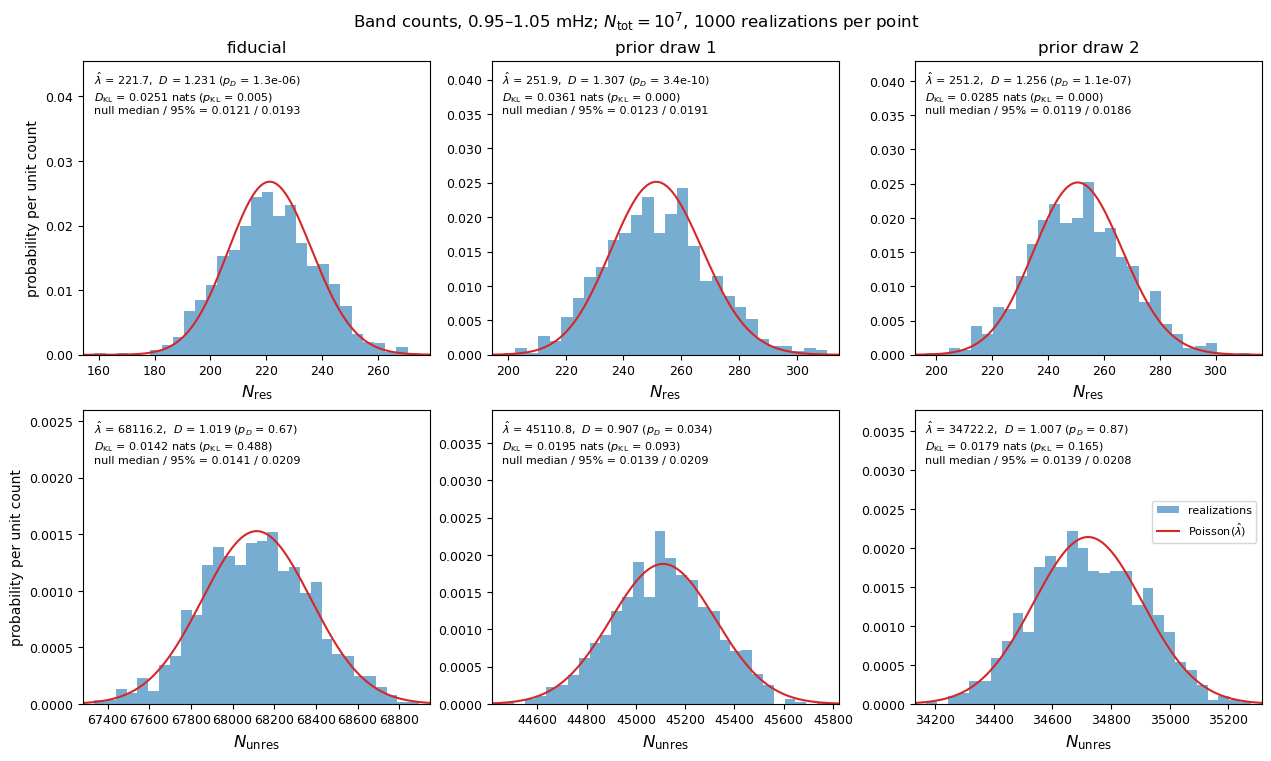

In [5]:
labels = {'N_res': r'$N_\mathrm{res}$', 'N_unres': r'$N_\mathrm{unres}$'}
fig, axes = plt.subplots(2, len(point_names), figsize=(4.2*len(point_names), 7.5), constrained_layout=True)
for j, p in enumerate(point_names):
    for i, qname in enumerate(quantities):
        ax = axes[i, j]
        r = results[(p, qname)]
        x = counts[p][qname]
        width = r['edges'][1] - r['edges'][0]
        ## empirical density per unit count on the KL bins, against the fitted Poisson pmf
        h = ax.hist(x, bins=r['edges'], density=True, color='C0', alpha=0.6, label='realizations')[0]
        k = np.arange(int(np.floor(r['lam'] - 5*np.sqrt(r['lam']))), int(np.ceil(r['lam'] + 5*np.sqrt(r['lam']))) + 1)
        k = k[k >= 0]
        ax.plot(k, ss.poisson.pmf(k, r['lam']), color='C3', lw=1.5, label=r'Poisson($\hat\lambda$)')
        ax.set_xlim(r['edges'][0] - width, r['edges'][-1] + width)
        ## headroom above the histogram for the statistics annotation
        ax.set_ylim(0, 1.7*max(h.max(), ss.poisson.pmf(np.round(r['lam']), r['lam'])))
        ax.set_xlabel(labels[qname], fontsize=12)
        ax.tick_params(labelsize=9)
        if j == 0:
            ax.set_ylabel('probability per unit count', fontsize=10)
        if i == 0:
            ax.set_title(p.replace('_', ' '), fontsize=12)
        txt = (rf"$\hat\lambda$ = {r['lam']:.1f},  $D$ = {r['D']:.3f} ($p_D$ = {r['p_D']:.2g})" + '\n'
               + rf"$D_\mathrm{{KL}}$ = {r['kl']:.4f} nats ($p_\mathrm{{KL}}$ = {np.mean(r['kl_null'] >= r['kl']):.3f})" + '\n'
               + rf"null median / 95% = {np.median(r['kl_null']):.4f} / {np.percentile(r['kl_null'], 95):.4f}")
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, va='top', ha='left', fontsize=8)
axes[1, -1].legend(loc='center right', fontsize=8, bbox_to_anchor=(1.0, 0.62))
fig.suptitle(rf"Band counts, 0.95–1.05 mHz; $N_\mathrm{{tot}} = 10^{{{np.log10(settings['ntot']):.0f}}}$, "
             rf"{int(settings['nreal'])} realizations per point", fontsize=12)
fig.savefig(os.path.join(DATA_DIR, 'poisson_counts_hist.png'), dpi=150)
plt.show()

### Interpretation

**$N_\mathrm{unres}$ is consistent with Poisson.** At the three points, $D$ = 1.019, 0.907 and 1.007, and the
binned KL lies inside its Poisson null ($p_\mathrm{KL}$ = 0.49, 0.09, 0.17). `prior_draw_1` is mildly
underdispersed ($p_D$ = 0.03). Among the six tests here, a single marginal value is weak evidence. The
binomial reduction from the fixed $N_\mathrm{tot}$, $D = 1 - p_\mathrm{band} \gtrsim 0.993$, is too small to
resolve with 1000 realizations.

**$N_\mathrm{res}$ is overdispersed relative to Poisson** at all three points. $D$ = 1.23, 1.31 and 1.26
($p_D < 10^{-5}$), and the binned KL lies outside the null ($p_\mathrm{KL} \le 0.005$). The shape is still
close to Poisson: unimodal and symmetric, with $D_\mathrm{KL}$ of 0.025–0.036 nats against a null median of
about 0.012. A Poisson with the same mean is about $\sqrt{D} - 1 \approx$ 11–14% too narrow in standard
deviation.

A possible origin, **not tested here**: independent per-binary thinning of a Poisson process would stay
Poisson. Thresholding, however, is not independent between binaries in a bin.
- The Eq. (17) boundary is set by an extreme value: the loudest sub-threshold source in the bin. One
  fluctuation in it moves several binaries across the line together.
- The cumulative confusion term in Eq. (16) depends on the realization's own unresolved population in that bin.

A per-bin study could test this.

**For context:** the paper's predictive for $N_\mathrm{res}$, Eq. (A8), is already a negative binomial with
variance $\approx (1 + 1/\beta')\times$ mean, i.e. about 1.2 for $N_r = 5$ realizations. That broadening
comes from the uncertainty in $\lambda$, not from intrinsic overdispersion of the counts. The overdispersion
measured here is comparable in size and would add to it.

# Study 1b: full toy-model band, fiducial point only

This repeats Study 1 over the **whole toy-model frequency range** with **only the Table 1 fiducial point**.
- **Grid:** $f_\mathrm{min} = 0.3$ mHz and $\Delta f = 5\times10^{-5}$ Hz, the toy-model values in the paper. The
  upper limit is $f_\mathrm{max} = 6$ mHz, giving 114 bins on 0.3–6 mHz plus a bin-0 catch-all below. The paper
  gives no explicit upper limit; 6 mHz is the `--fmax` of the recorded toy-model runs
  (`results/test_runs/57-vt`–`59-vt`).
- **Draws:** $N_\mathrm{tot} = 10^7$ binaries per realization, 1000 realizations, $\rho_\mathrm{thresh} = 7$.
- **Statistics:** computed for
  1. the full-band totals, and
  2. **sub-bands of width $10^{-4}$ Hz**, the width of the Study 1 band. That is 2 toy-model bins each,
     giving 57 sub-bands.

Per-bin counts are saved, so a different sub-band width can be chosen after loading without re-simulating.

**Per-bin counting.** `block_array_sort` returns only the sum of $N_\mathrm{res}$ over bins. Here each bin is
thresholded separately with the library's `SNR_Threshold.per_frequency_array_sort`, so the counts follow the same
rule (Eq. 17). One zero-amplitude entry is prepended to each bin, which mirrors the zero-padding of the blocked
path. Without it, the per-bin routine drops the faintest source of a bin whose sources are *all* above
threshold (the strict xfail in `tests/test_thresholding.py`). The pilot cell checks that the per-bin totals equal
`block_array_sort`'s $N_\mathrm{res}$ realization by realization.

## Simulation (full band)

In [3]:
import os
import sys
import time

## pelargir (main branch) picks its array backend at import time
os.environ['PELARGIR_GPU'] = '1'
sys.path.insert(1, '../pelargir/')

import numpy as np
from tqdm import tqdm

from models import PopModel, xp
from inference import PopulationHyperPrior
from utils import get_amp_freq, to_numpy

BACKEND = 'cupy' if xp is not np else 'numpy'
## Disable cupy's CUB reduction kernels. With them on, device memory outside the memory pool grew by about
## 35-40 MB per realization on this 114-bin grid, until CUDA_ERROR_OUT_OF_MEMORY after about 350 realizations
## (8 GB GPU). With them off, memory stays flat and each realization is about 3x faster. Root cause not
## investigated. A runtime call rather than CUPY_ACCELERATORS, because cupy may already be imported (Study 1).
if xp is not np:
    xp._core.set_reduction_accelerators([])

## ---- settings ----
NTOT = int(1e7)       ## binaries per galaxy, fixed per realization
NREAL = 1000          ## galaxy realizations
SNR_THRESH = 7.0
FB_SEED = 20261124    ## galaxy draws for this study
FMIN = 3e-4           ## toy-model f_min [Hz]
FMAX = 6e-3           ## upper edge [Hz] ## REQUIRES INPUT/VERIFICATION: not stated in the paper; --fmax of results/test_runs/57-59-vt
FBIN = 5e-5           ## toy-model bin width [Hz]
FIDUCIAL = dict(m_mu=0.6, m_sigma=0.15, rh_disk=3.31, r_bulge=0.75, q_bd=0.33, a_alpha=0.5)  ## Table 1

DATA_DIR = 'reviewer-response-data'
FB_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband.npz')
os.makedirs(DATA_DIR, exist_ok=True)

## bin centres FMIN + FBIN*(k - 1/2), k = 0..NB: bin 0 (0.275 mHz) is the catch-all below FMIN and bins
## 1..NB tile [FMIN, FMAX) exactly; built from integers to avoid arange end-point rounding
NB = int(round((FMAX - FMIN)/FBIN))
fb_fbins = FMIN + FBIN*(xp.arange(NB + 1) - 0.5)
print(f"{NB} bins on [{FMIN*1e3:.2f}, {FMAX*1e3:.2f}) mHz; backend {BACKEND}")

fb_rng = xp.random.default_rng(FB_SEED)
fb_popmodel = PopModel(NTOT, fb_rng, hyperprior=PopulationHyperPrior(fb_rng), fbins=fb_fbins, Nreal=1,
                       threshold_val=SNR_THRESH)

GPU requested and available; running Pelargir population inference on GPU.


GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
GPU requested and available; running Pelargir population inference on GPU.
114 bins on [0.30, 6.00) mHz; backend cupy


In [4]:
def count_per_bin(popmodel, pop_theta, return_obs=False):
    '''

    Draw one galaxy realization and count resolved and in-band binaries in every frequency bin above the
    bin-0 catch-all, thresholding each bin with SNR_Threshold.per_frequency_array_sort.

    Arguments
    ------------------------------
    popmodel : PopModel
    	Population model (Nreal=1); its gbprior draws popmodel.N binaries per call.
    pop_theta : dict
    	Population hyperparameters, {name: float}.
    return_obs : bool
    	Also return the (frequency, amplitude) array of the draw, for cross-checks. (Default: False)

    Returns
    ------------------------------
    nres_f : numpy.ndarray
    	Resolved binaries per bin, shape (Nf - 1,) for bins 1..Nf-1.
    nin_f : numpy.ndarray
    	Binaries per bin (resolved + unresolved), shape (Nf - 1,).
    obs : cupy.ndarray or numpy.ndarray
    	(2, N) array of (f_gw [Hz], amplitude); only returned if return_obs.

    '''
    thr = popmodel.thresher
    Nf = len(popmodel.fbins)
    ## condition() reshapes its input in place, so pass fresh arrays each time
    popmodel.gbprior.condition({k: xp.array([v]) for k, v in pop_theta.items()})
    galaxy_draw = popmodel.gbprior.sample_conditional(popmodel.N)
    amp, fgw = get_amp_freq(galaxy_draw)
    obs = xp.array([fgw.ravel(), amp.ravel()])
    ## f_idx = k for f in [f_k - df/2, f_k + df/2); bin 0 collects everything below, Nf everything above
    amps, f_idx = thr.coarsegrain_bin(obs, popmodel.fbins)
    ## group binaries by bin with one sort, rather than one full-length mask per bin
    bin_counts = xp.bincount(f_idx, minlength=Nf + 1)
    offsets = np.concatenate([[0], np.cumsum(to_numpy(bin_counts))])
    amps_by_bin = amps[xp.argsort(f_idx)]
    zero = xp.zeros(1)
    nres_f = np.zeros(Nf, dtype=np.int64)
    for k in range(1, Nf):
        ## response-weighted amplitudes, as in serial_array_sort; the prepended zero mirrors the block path's
        ## zero-padding, so a bin whose sources are all above threshold keeps all of them
        a_k = amps_by_bin[offsets[k]:offsets[k + 1]]*xp.sqrt(thr.LISA_rx[k])
        a_k = xp.concatenate([zero, a_k])[:, None, None]
        nres_k, _ = thr.per_frequency_array_sort(a_k, thr.noisePSD[k], snr_thresh=popmodel.thresh_val)
        nres_f[k] = int(to_numpy(nres_k).squeeze())
    nin_f = to_numpy(bin_counts[1:Nf]).astype(np.int64)
    del galaxy_draw, amp, fgw, amps, f_idx, amps_by_bin
    if return_obs:
        return nres_f[1:], nin_f, obs
    del obs
    if xp is not np:
        xp.get_default_memory_pool().free_all_blocks()
    return nres_f[1:], nin_f

### Pilot: timing and cross-check against `block_array_sort` (5 realizations)

In [4]:
t0 = time.time()
for i in range(5):
    nres_f, nin_f, obs = count_per_bin(fb_popmodel, FIDUCIAL, return_obs=True)
    nres_block, _ = fb_popmodel.thresher.block_array_sort(obs, fb_fbins, snr_thresh=SNR_THRESH)
    assert nres_f.sum() == int(to_numpy(nres_block)), (nres_f.sum(), int(to_numpy(nres_block)))
    print(f"realization {i}: N_res = {nres_f.sum()} (block_array_sort: {int(to_numpy(nres_block))}), "
          f"N_in = {nin_f.sum()}, min N_res per bin = {nres_f.min()}, min N_unres per bin = {(nin_f - nres_f).min()}")
    del obs
    if xp is not np:
        xp.get_default_memory_pool().free_all_blocks()
dt = (time.time() - t0)/5
print(f"{dt:.2f} s per realization incl. the block cross-check -> roughly {dt*NREAL/60:.0f} min upper bound for the full run")

realization 0: N_res = 8694 (block_array_sort: 8694), N_in = 2164554, min N_res per bin = 35, min N_unres per bin = 786


realization 1: N_res = 8702 (block_array_sort: 8702), N_in = 2163516, min N_res per bin = 38, min N_unres per bin = 833


realization 2: N_res = 8972 (block_array_sort: 8972), N_in = 2165486, min N_res per bin = 46, min N_unres per bin = 830


realization 3: N_res = 8965 (block_array_sort: 8965), N_in = 2163742, min N_res per bin = 41, min N_unres per bin = 805


realization 4: N_res = 8786 (block_array_sort: 8786), N_in = 2163250, min N_res per bin = 38, min N_unres per bin = 807
1.12 s per realization incl. the block cross-check -> roughly 19 min upper bound for the full run


### Full run and save

In [5]:
fb_nres = np.empty((NREAL, NB), dtype=np.int64)
fb_nin = np.empty((NREAL, NB), dtype=np.int64)
t0 = time.time()
for i in tqdm(range(NREAL)):
    fb_nres[i], fb_nin[i] = count_per_bin(fb_popmodel, FIDUCIAL)
print(f"{(time.time() - t0)/NREAL:.2f} s per realization")
assert np.all(fb_nin >= fb_nres)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:00<03:11,  5.22it/s]

  0%|          | 2/1000 [00:00<03:11,  5.20it/s]

  0%|          | 3/1000 [00:00<03:11,  5.22it/s]

  0%|          | 4/1000 [00:00<03:14,  5.12it/s]

  0%|          | 5/1000 [00:00<03:12,  5.16it/s]

... (993 outputs left out)

100%|█████████▉| 999/1000 [03:14<00:00,  5.15it/s]

100%|██████████| 1000/1000 [03:14<00:00,  5.14it/s]

100%|██████████| 1000/1000 [03:14<00:00,  5.14it/s]

0.19 s per realization


In [6]:
## flat npz (no pickles): per-bin counts of shape (NREAL, NB) for bins 1..NB (centres fbins[1:])
np.savez(FB_DATA_FILE,
         N_res_f=fb_nres, N_in_f=fb_nin, fbins=to_numpy(fb_fbins),
         hpar_names=np.array(list(FIDUCIAL)), theta=np.array(list(FIDUCIAL.values())),
         ntot=NTOT, nreal=NREAL, snr_thresh=SNR_THRESH, sim_seed=FB_SEED, fmin=FMIN, fmax=FMAX, fbin=FBIN,
         backend=BACKEND)
print("saved", FB_DATA_FILE)

saved reviewer-response-data/poisson_counts_fullband.npz


## Load data (full band)

**Restart point.** Run the two helper cells at the top first. The cells below use only the objects loaded
here, plus numpy, scipy, pandas and matplotlib.

`SUBBAND_WIDTH` sets the sub-band width. It must be a whole number of bins, and any bins left over at the top of
the band are dropped.

In [5]:
DATA_DIR = 'reviewer-response-data'
FB_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband.npz')
SUBBAND_WIDTH = 1e-4   ## [Hz], the width of the Study 1 band

fb_data = load_fullband(FB_DATA_FILE, SUBBAND_WIDTH)
m = fb_data['meta']
print(f"{fb_data['nreal']} realizations x {m['N_res_f'].shape[1]} bins of {m['fbin']:.0e} Hz on "
      f"[{m['fmin']*1e3:.2f}, {m['fmax']*1e3:.2f}) mHz; fixed N_tot = {int(m['ntot']):.0e}; "
      f"theta = {dict(zip(m['hpar_names'].tolist(), m['theta'].tolist()))}")
print(f"{fb_data['n_sub']} sub-bands of {SUBBAND_WIDTH:.0e} Hz")

1000 realizations x 114 bins of 5e-05 Hz on [0.30, 6.00) mHz; fixed N_tot = 1e+07; theta = {'m_mu': 0.6, 'm_sigma': 0.15, 'rh_disk': 3.31, 'r_bulge': 0.75, 'q_bd': 0.33, 'a_alpha': 0.5}
57 sub-bands of 1e-04 Hz


## Statistics (full band)

The same tests as Study 1 are used: binned KL against a 1000-replicate parametric-bootstrap Poisson null, and
the dispersion index $D$.

With fixed $N_\mathrm{tot}$, the in-band count is binomial, with
$D_\mathrm{ref}(N_\mathrm{in}) = D_\mathrm{binom} = 1 - \bar N_\mathrm{in}/N_\mathrm{tot}$.
Over the full band about 22% of all binaries fall in band, so this reference is now well below 1 and
**resolvable**. It is shown alongside the results as the expectation for a fixed-$N_\mathrm{tot}$ count that
involves no thresholding.

In [6]:
fb_results, fb_summary = fullband_poisson_summary(fb_data, np.random.default_rng(12))
pd.options.display.float_format = '{:.4g}'.format
fb_summary.loc['full band']

   N_res: 57 sub-bands; median D = 1.088 (range 0.978-1.321); p_D < 0.05 in 28, p_KL < 0.05 in 12 (expected by chance: 2.9)
 N_unres: 57 sub-bands; median D = 1.026 (range 0.893-1.127); p_D < 0.05 in 9, p_KL < 0.05 in 5 (expected by chance: 2.9)


,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
quantity,,,,,,,,,
N_res,8802,1.016e+04,1.154,0.000966,0.0206,0.01397,0.02075,0.056,0.7835
N_unres,2.156e+06,1.836e+06,0.8516,0.0004981,0.01956,0.01409,0.02096,0.089,0.7835


In [7]:
fb_summary.drop('full band', level='band')

,,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
band,quantity,,,,,,,,,
0.3-0.4 mHz,N_res,248.9,328.9,1.321,5.847e-11,0.04555,0.01217,0.01866,0,0.9423
0.4-0.5 mHz,N_res,248.1,280,1.128,0.005615,0.01908,0.01209,0.01893,0.042,0.9655
0.5-0.6 mHz,N_res,242.9,289.7,1.193,4.612e-05,0.01547,0.01202,0.01899,0.193,0.9771
0.6-0.7 mHz,N_res,240.4,307,1.277,1.137e-08,0.02674,0.0122,0.01956,0.003,0.9836
0.7-0.8 mHz,N_res,234.5,298.6,1.273,1.725e-08,0.0304,0.01202,0.01904,0,0.9878
...,...,...,...,...,...,...,...,...,...,...
5.5-5.6 mHz,N_unres,1953,2098,1.074,0.1025,0.01222,0.01364,0.02033,0.662,0.9998
5.6-5.7 mHz,N_unres,1876,2109,1.124,0.00721,0.01929,0.01359,0.02044,0.086,0.9998
5.7-5.8 mHz,N_unres,1806,2000,1.107,0.02,0.02866,0.01353,0.02063,0,0.9998


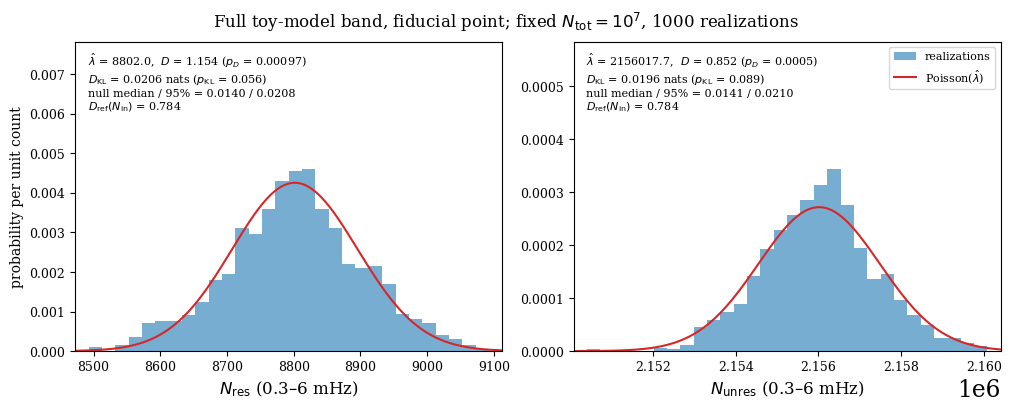

In [8]:
plot_fullband_hist(fb_data, fb_results,
                   rf"Full toy-model band, fiducial point; fixed $N_\mathrm{{tot}} = 10^{{{np.log10(fb_data['meta']['ntot']):.0f}}}$, "
                   rf"{fb_data['nreal']} realizations",
                   os.path.join(DATA_DIR, 'poisson_counts_fullband_hist.png'))
plt.show()

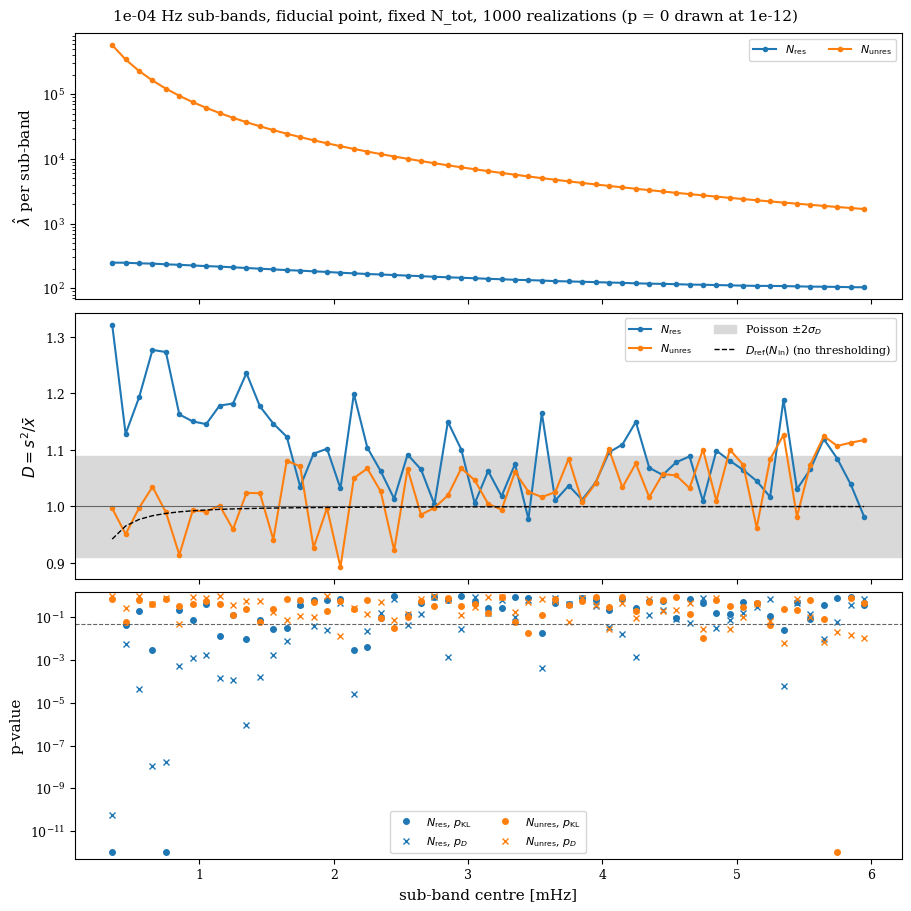

In [9]:
plot_subband_diagnostics(fb_data, fb_summary,
                         rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, fixed N_tot, {fb_data['nreal']} realizations",
                         os.path.join(DATA_DIR, 'poisson_counts_subbands.png'))
plt.show()

### Diagnostic: is thresholding an independent thinning?

If each in-band binary were resolved independently with a fixed probability, Poisson in-band counts would give
**independent** Poisson $N_\mathrm{res}$ and $N_\mathrm{unres}$. In that case
$\mathrm{corr}(N_\mathrm{res}, N_\mathrm{in}) = \sqrt{\lambda_\mathrm{res}/\lambda_\mathrm{in}}$.

The cell below compares this with the simulations, sub-band by sub-band. It also checks the dispersion of the
in-band count itself. Finally, it predicts $D(N_\mathrm{unres})$ from $N_\mathrm{unres} = N_\mathrm{in} - N_\mathrm{res}$,
assuming $N_\mathrm{res}$ is uncorrelated with $N_\mathrm{in}$:

$D_\mathrm{unres} \approx (\lambda_\mathrm{in} D_\mathrm{in} + \lambda_\mathrm{res} D_\mathrm{res})/\lambda_\mathrm{unres}$

mean corr(N_res, N_in) over sub-bands: 0.027 (independent thinning: 0.141; 1-sigma noise per sub-band ~0.032)
mean D(N_in) over sub-bands: 0.987; full-band D(N_in) = 0.850 vs no-thresholding reference 0.784
mean correlation of N_res between different sub-bands: 0.0007


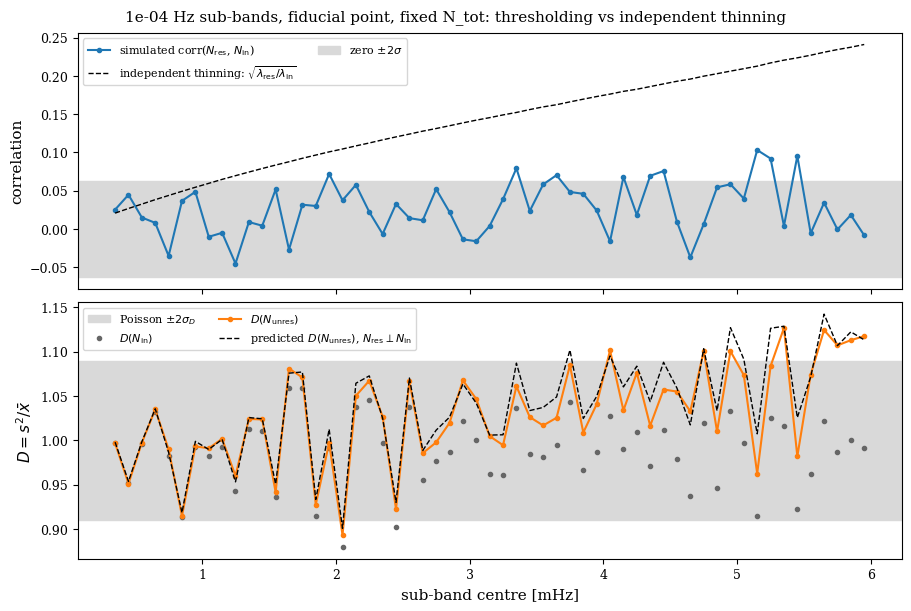

In [10]:
fb_diag = thinning_diagnostic(fb_data, rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, fixed N_tot: "
                                       "thresholding vs independent thinning",
                              os.path.join(DATA_DIR, 'poisson_counts_thinning_diagnostic.png'))
plt.show()

### Interpretation (full band)

**Full band (0.3–6 mHz).**
- **$N_\mathrm{res}$** ($\hat\lambda = 8802$): overdispersed, $D = 1.15$ ($p_D = 10^{-3}$). The binned KL is marginal
  ($p_\mathrm{KL} = 0.056$). The excess is simply the sum of the sub-band excesses. The sub-band variances
  add to 9800 of the total variance of 10160, and the mean correlation of $N_\mathrm{res}$ between different
  sub-bands is $7\times10^{-4}$.
- **$N_\mathrm{unres}$** ($\hat\lambda = 2.16\times10^6$): *under*dispersed, $D = 0.85$ ($p_D = 5\times10^{-4}$).
  - This comes from the fixed-$N_\mathrm{tot}$ construction, not from thresholding. About 22% of all binaries
    fall in 0.3–6 mHz, so the in-band count is binomial with $D_\mathrm{binom} = 0.78$.
  - The measured $D(N_\mathrm{in}) = 0.85$ agrees with that to $1.5\sigma_D$.
  - With a Poisson-distributed $N_\mathrm{tot}$, the point-process picture of footnote 4, this deviation would vanish.

**Sub-bands of $10^{-4}$ Hz (57).**
- **$N_\mathrm{res}$:** overdispersed throughout, most strongly below about 2 mHz ($D$ = 1.04–1.32, mostly above 1.1).
  Above that, $D$ = 0.98–1.20. 28 of 57 sub-bands have $p_D < 0.05$, and 12 have $p_\mathrm{KL} < 0.05$,
  against 2.9 expected by chance.
- **$N_\mathrm{unres}$:** consistent with Poisson below about 4 mHz. Above that, $D$ = 0.96–1.13, mostly 1.03–1.13.
  9 of 57 sub-bands have $p_D < 0.05$, and 5 have $p_\mathrm{KL} < 0.05$.

**Mechanism, from the thinning diagnostic.**
- The number of resolved binaries in a sub-band is nearly **independent of how many binaries it contains**.
  The mean $\mathrm{corr}(N_\mathrm{res}, N_\mathrm{in})$ is 0.027. Independent thinning would give
  $\sqrt{\lambda_\mathrm{res}/\lambda_\mathrm{in}}$ = 0.02–0.24, rising with frequency. More binaries in a bin
  raise the confusion level and with it the boundary of Eq. (17).
- So thresholding is not an independent thinning, and $N_\mathrm{unres} = N_\mathrm{in} - N_\mathrm{res}$
  inherits the variance of $N_\mathrm{res}$.
- The prediction $D_\mathrm{unres} \approx (\lambda_\mathrm{in}D_\mathrm{in} + \lambda_\mathrm{res}D_\mathrm{res})/\lambda_\mathrm{unres}$
  tracks the measured $D(N_\mathrm{unres})$ across the band.
- The effect is visible only where $\lambda_\mathrm{res}/\lambda_\mathrm{in}$ reaches a few percent, at
  $f \gtrsim 4$ mHz.

The in-band count itself behaves as expected: the mean $D(N_\mathrm{in})$ over sub-bands is 0.987.

**Consistency with Study 1.** Study 1 used $\Delta f = 10^{-5}$ Hz and found $D(N_\mathrm{res}) = 1.23$ at
0.95–1.05 mHz. Here the neighbouring sub-bands give 1.15. Different bin widths change the per-bin confusion
level and the boundary, so the two values need not agree exactly. Both show the same sign and size of
effect.

**For the reply.**
- At the toy-model resolution, a Poisson model for $N_\mathrm{res}$ in $10^{-4}$ Hz sub-bands underestimates
  the variance by up to about 30% below 2 mHz, and by about 0–20% above.
- $N_\mathrm{unres}$ is Poisson to within about 13% in variance in every sub-band ($D$ = 0.89–1.13).
- All distributions remain unimodal and close to Poisson in shape: $D_\mathrm{KL}$ = 0.007–0.046 nats
  across sub-bands, against a null median of about 0.012–0.014.

# Study 1c: Poisson-distributed $N_\mathrm{tot}$ (fixed $\lambda_\mathrm{tot}$), full toy-model band, fiducial point

Studies 1 and 1b fix $N_\mathrm{tot}$ in every realization, which makes the in-band count binomial. In Study 1b the
full-band $N_\mathrm{unres}$ is underdispersed ($D = 0.85$), and the claim there is that this comes from
fixing $N_\mathrm{tot}$.

This study tests that claim. It fixes the rate $\lambda_\mathrm{tot} = 10^7$ and draws
$N_\mathrm{tot} \sim \mathrm{Poisson}(\lambda_\mathrm{tot})$ independently for each realization. This is the
Poisson point-process picture of the paper's footnote 4. By Poisson thinning, the in-band count is then exactly
$\mathrm{Poisson}(\lambda_\mathrm{tot}\,p_\mathrm{band})$, so $D_\mathrm{ref}(N_\mathrm{in}) = 1$ in every band.

Everything else matches Study 1b: the toy grid (0.3–6 mHz, $\Delta f = 5\times10^{-5}$ Hz), the fiducial point,
$\rho_\mathrm{thresh} = 7$, 1000 realizations, the same per-bin thresholding (`count_per_bin`), and the same
statistics on the full band and on $10^{-4}$ Hz sub-bands.

**Expectations if the Study 1b reading is right:**
- **Full-band $N_\mathrm{unres}$:** $D \approx 1$, up to the small $N_\mathrm{res}$-variance contribution from
  the thinning diagnostic, about $(1 + D_\mathrm{res})\lambda_\mathrm{res}/\lambda_\mathrm{in} \approx 0.009$.
- **Full-band $N_\mathrm{in}$:** $D \approx 1$.
- **Sub-bands:** essentially unchanged from 1b, since each holds $\lesssim 6\%$ of all binaries.

**Before simulating:** run the Study 1b setup cell and its `count_per_bin` cell. Do not run 1b's pilot or
full run. This study reuses 1b's grid, settings and counting function.

## Simulation (Poisson $N_\mathrm{tot}$)

In [11]:
LAMBDA_TOT = int(1e7)   ## Poisson rate of the total number of binaries per galaxy
FC_SEED = 20261125      ## galaxy draws for this study
NTOT_SEED = 20261126    ## N_tot draws
FC_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot.npz')

## N_tot ~ Poisson(lambda_tot), one per realization
fc_ntot = np.random.default_rng(NTOT_SEED).poisson(LAMBDA_TOT, size=NREAL)
print(f"N_tot: mean {fc_ntot.mean():.1f}, var/mean {fc_ntot.var(ddof=1)/fc_ntot.mean():.3f}, "
      f"range {fc_ntot.min()}-{fc_ntot.max()}")

fc_rng = xp.random.default_rng(FC_SEED)
fc_popmodel = PopModel(LAMBDA_TOT, fc_rng, hyperprior=PopulationHyperPrior(fc_rng), fbins=fb_fbins, Nreal=1,
                       threshold_val=SNR_THRESH)

fc_nres = np.empty((NREAL, NB), dtype=np.int64)
fc_nin = np.empty((NREAL, NB), dtype=np.int64)
t0 = time.time()
for i in tqdm(range(NREAL)):
    ## count_per_bin draws popmodel.N binaries, so set it to this realization's N_tot
    fc_popmodel.N = int(fc_ntot[i])
    fc_nres[i], fc_nin[i] = count_per_bin(fc_popmodel, FIDUCIAL)
print(f"{(time.time() - t0)/NREAL:.2f} s per realization")
assert np.all(fc_nin >= fc_nres)

N_tot: mean 9999966.3, var/mean 1.012, range 9991094-10008890


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:00<03:34,  4.65it/s]

  0%|          | 2/1000 [00:00<03:19,  5.00it/s]

  0%|          | 3/1000 [00:00<03:14,  5.14it/s]

  0%|          | 4/1000 [00:00<03:11,  5.19it/s]

... (994 outputs left out)

100%|█████████▉| 999/1000 [03:14<00:00,  5.09it/s]

100%|██████████| 1000/1000 [03:14<00:00,  5.10it/s]

100%|██████████| 1000/1000 [03:14<00:00,  5.14it/s]

0.19 s per realization


In [12]:
## flat npz (no pickles), as Study 1b; 'ntot' is now the per-realization N_tot and 'lambda_tot' marks Poisson N_tot
np.savez(FC_DATA_FILE,
         N_res_f=fc_nres, N_in_f=fc_nin, fbins=to_numpy(fb_fbins),
         hpar_names=np.array(list(FIDUCIAL)), theta=np.array(list(FIDUCIAL.values())),
         ntot=fc_ntot, lambda_tot=LAMBDA_TOT, nreal=NREAL, snr_thresh=SNR_THRESH, sim_seed=FC_SEED,
         ntot_seed=NTOT_SEED, fmin=FMIN, fmax=FMAX, fbin=FBIN, backend=BACKEND)
print("saved", FC_DATA_FILE)

saved reviewer-response-data/poisson_counts_fullband_poissonNtot.npz


## Load data (Poisson $N_\mathrm{tot}$)

**Restart point.** Run the two helper cells at the top first. The comparison with Study 1b below also loads the
Study 1b file.

In [13]:
DATA_DIR = 'reviewer-response-data'
FC_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot.npz')
SUBBAND_WIDTH = 1e-4   ## [Hz], the width of the Study 1 band

fc_data = load_fullband(FC_DATA_FILE, SUBBAND_WIDTH)
m = fc_data['meta']
print(f"{fc_data['nreal']} realizations x {m['N_res_f'].shape[1]} bins of {m['fbin']:.0e} Hz on "
      f"[{m['fmin']*1e3:.2f}, {m['fmax']*1e3:.2f}) mHz; N_tot ~ Poisson({int(m['lambda_tot']):.0e}) "
      f"(sample mean {m['ntot'].mean():.1f}, D = {m['ntot'].var(ddof=1)/m['ntot'].mean():.3f}); "
      f"theta = {dict(zip(m['hpar_names'].tolist(), m['theta'].tolist()))}")
print(f"{fc_data['n_sub']} sub-bands of {SUBBAND_WIDTH:.0e} Hz")

1000 realizations x 114 bins of 5e-05 Hz on [0.30, 6.00) mHz; N_tot ~ Poisson(1e+07) (sample mean 9999966.3, D = 1.012); theta = {'m_mu': 0.6, 'm_sigma': 0.15, 'rh_disk': 3.31, 'r_bulge': 0.75, 'q_bd': 0.33, 'a_alpha': 0.5}
57 sub-bands of 1e-04 Hz


## Statistics (Poisson $N_\mathrm{tot}$)

The same tests as Study 1b are used. $D_\mathrm{ref}(N_\mathrm{in}) = 1$ everywhere.

In [14]:
fc_results, fc_summary = fullband_poisson_summary(fc_data, np.random.default_rng(13))
pd.options.display.float_format = '{:.4g}'.format
fc_summary.loc['full band']

   N_res: 57 sub-bands; median D = 1.085 (range 0.966-1.281); p_D < 0.05 in 27, p_KL < 0.05 in 14 (expected by chance: 2.9)
 N_unres: 57 sub-bands; median D = 1.043 (range 0.915-1.161); p_D < 0.05 in 11, p_KL < 0.05 in 3 (expected by chance: 2.9)


,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
quantity,,,,,,,,,
N_res,8798,1.073e+04,1.219,4.31e-06,0.01802,0.01384,0.02113,0.157,1
N_unres,2.156e+06,2.127e+06,0.9867,0.7766,0.01753,0.01381,0.02085,0.17,1


In [15]:
fc_summary.drop('full band', level='band')

,,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
band,quantity,,,,,,,,,
0.3-0.4 mHz,N_res,248.1,315.1,1.27,2.446e-08,0.03508,0.012,0.01887,0,1
0.4-0.5 mHz,N_res,247.1,316.4,1.281,7.39e-09,0.02408,0.01225,0.0195,0.006,1
0.5-0.6 mHz,N_res,243.3,308.1,1.266,3.637e-08,0.02762,0.01217,0.01908,0.002,1
0.6-0.7 mHz,N_res,239.6,298.3,1.245,3.446e-07,0.02158,0.01195,0.01874,0.013,1
0.7-0.8 mHz,N_res,235.5,266.9,1.133,0.004062,0.009023,0.01192,0.01906,0.792,1
...,...,...,...,...,...,...,...,...,...,...
5.5-5.6 mHz,N_unres,1954,2023,1.035,0.4314,0.01552,0.01347,0.02079,0.308,1
5.6-5.7 mHz,N_unres,1879,1998,1.063,0.16,0.008896,0.01341,0.01987,0.933,1
5.7-5.8 mHz,N_unres,1808,1834,1.014,0.7399,0.01438,0.01356,0.02024,0.415,1


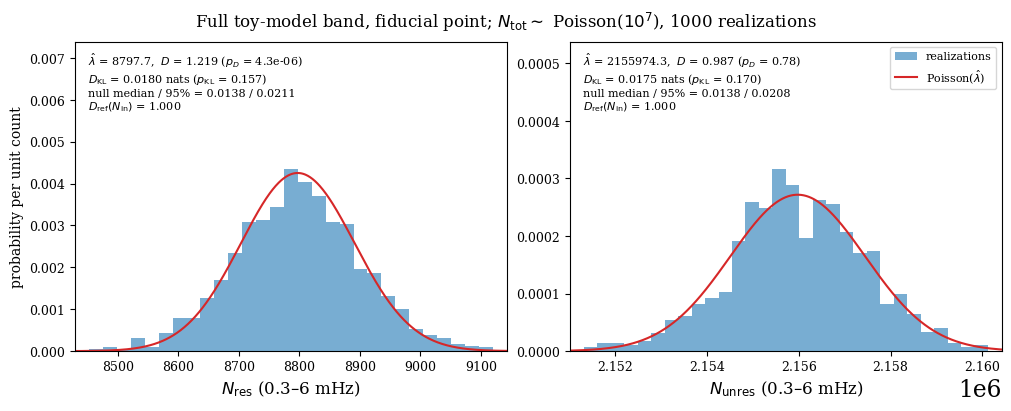

In [16]:
plot_fullband_hist(fc_data, fc_results,
                   rf"Full toy-model band, fiducial point; $N_\mathrm{{tot}} \sim$ Poisson($10^{{{np.log10(fc_data['meta']['lambda_tot']):.0f}}}$), "
                   rf"{fc_data['nreal']} realizations",
                   os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot_hist.png'))
plt.show()

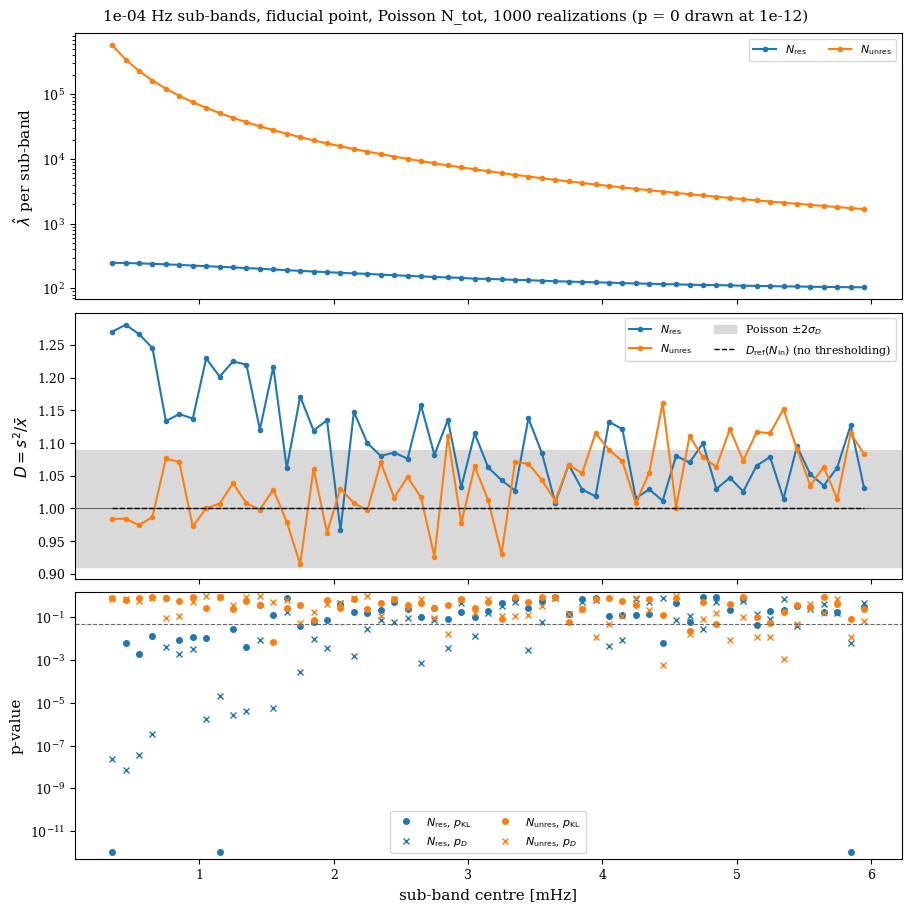

In [17]:
plot_subband_diagnostics(fc_data, fc_summary,
                         rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson N_tot, {fc_data['nreal']} realizations",
                         os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_subbands.png'))
plt.show()

mean corr(N_res, N_in) over sub-bands: 0.034 (independent thinning: 0.141; 1-sigma noise per sub-band ~0.032)
mean D(N_in) over sub-bands: 1.001; full-band D(N_in) = 0.978 vs no-thresholding reference 1.000
mean correlation of N_res between different sub-bands: 0.0017


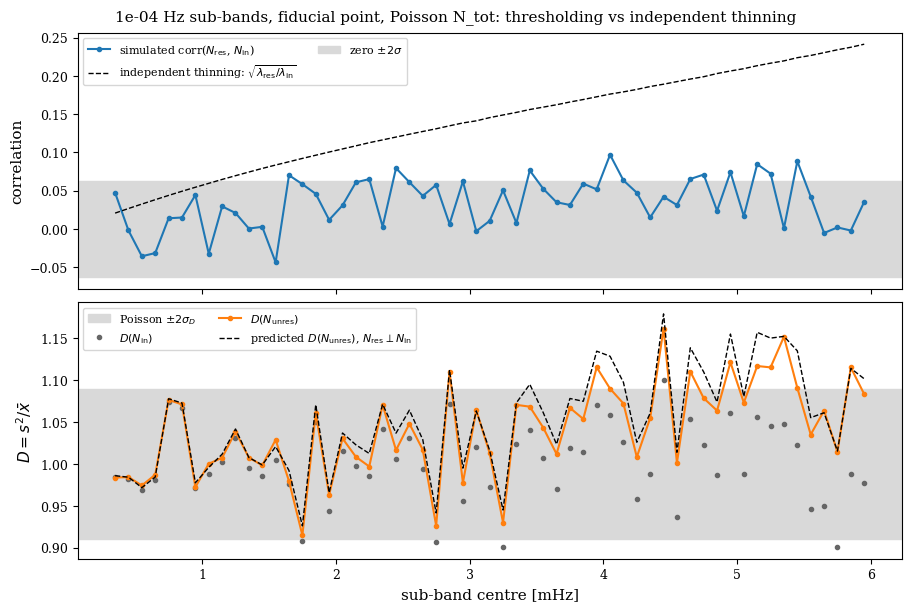

In [18]:
fc_diag = thinning_diagnostic(fc_data, rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson N_tot: "
                                       "thresholding vs independent thinning",
                              os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_thinning_diagnostic.png'))
plt.show()

### Comparison with Study 1b (fixed $N_\mathrm{tot}$)

Full-band dispersion indices side by side, and the sub-band $D$ of both studies against frequency. The two studies
use independent galaxy draws, so sub-band differences within about $2\sqrt{2}\,\sigma_D \approx 0.13$ are
consistent with noise.

,D(N_in),p_D(N_in),D(N_res),p_D(N_res),D(N_unres),p_D(N_unres),D_ref(N_in)
study,,,,,,,
fixed N_tot (1b),0.8497,0.0004191,1.154,0.000966,0.8516,0.0004981,0.7835
Poisson N_tot (1c),0.9782,0.6342,1.219,4.31e-06,0.9867,0.7766,1


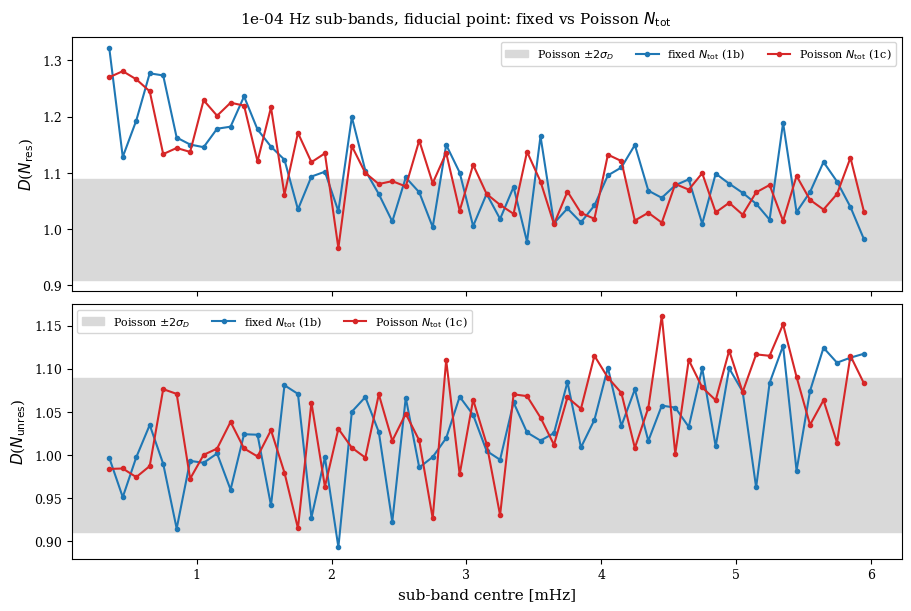

In [19]:
fb_cmp = load_fullband(os.path.join(DATA_DIR, 'poisson_counts_fullband.npz'), SUBBAND_WIDTH)
rows = []
for label, d in [('fixed N_tot (1b)', fb_cmp), ('Poisson N_tot (1c)', fc_data)]:
    row = {'study': label}
    for q in ['N_in', 'N_res', 'N_unres']:
        x = d['full'][q]
        D, p_D = dispersion_index(x)
        row[f'D({q})'], row[f'p_D({q})'] = D, p_D
    row['D_ref(N_in)'] = d['D_ref_full']
    rows.append(row)
display(pd.DataFrame(rows).set_index('study'))

sigma_D = np.sqrt(2/(fc_data['nreal'] - 1))
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, q in zip(axes, ['N_res', 'N_unres']):
    ax.axhspan(1 - 2*sigma_D, 1 + 2*sigma_D, color='0.85', label=r'Poisson $\pm 2\sigma_D$')
    for label, d, c in [('fixed $N_\\mathrm{tot}$ (1b)', fb_cmp, 'C0'), ('Poisson $N_\\mathrm{tot}$ (1c)', fc_data, 'C3')]:
        x = d['sub'][q]
        ax.plot(d['sub_centres']*1e3, x.var(axis=0, ddof=1)/x.mean(axis=0), 'o-', ms=3, color=c, label=label)
    ax.set_ylabel(rf"$D$({FB_LABELS[q]})", fontsize=11)
    ax.legend(fontsize=8, ncol=3)
    ax.tick_params(labelsize=9)
axes[1].set_xlabel('sub-band centre [mHz]', fontsize=11)
fig.suptitle(rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point: fixed vs Poisson $N_\mathrm{{tot}}$", fontsize=11)
fig.savefig(os.path.join(DATA_DIR, 'poisson_counts_fixed_vs_poissonNtot.png'), dpi=150)
plt.show()

### Interpretation (Poisson $N_\mathrm{tot}$)

**The Study 1b claim holds.** With $N_\mathrm{tot} \sim \mathrm{Poisson}(10^7)$, whose sample has $D = 1.012$,
the full-band counts that involve no thresholding are Poisson:

| full band (0.3–6 mHz) | fixed $N_\mathrm{tot}$ (1b) | Poisson $N_\mathrm{tot}$ (1c) |
|---|---|---|
| $D(N_\mathrm{in})$ | 0.850 (binomial reference 0.78) | 0.978 ($p_D$ = 0.63) |
| $D(N_\mathrm{unres})$ | 0.852 ($p_D = 5\times10^{-4}$) | 0.987 ($p_D$ = 0.78, $p_\mathrm{KL}$ = 0.17) |
| $D(N_\mathrm{res})$ | 1.154 ($p_D = 10^{-3}$) | 1.219 ($p_D = 4\times10^{-6}$) |

- **Full-band $N_\mathrm{unres}$ is consistent with Poisson** once $N_\mathrm{tot}$ is Poisson. The binned KL
  also lies inside its null.
- The thinning diagnostic adds only $(1 + D_\mathrm{res})\lambda_\mathrm{res}/\lambda_\mathrm{in} \approx 0.009$
  to the expected $D$. That is well below $\sigma_D \approx 0.045$.
- The underdispersion seen in Study 1b therefore came entirely from the fixed-$N_\mathrm{tot}$ construction.

**$N_\mathrm{res}$ remains overdispersed.** In the full band $D = 1.22$. The difference from Study 1b's 1.15 is
about $1\sigma$ of the difference, given independent draws ($\sqrt2\,\sigma_D \approx 0.064$). So the excess
variance of $N_\mathrm{res}$ is a property of the thresholding, not of how $N_\mathrm{tot}$ is drawn. The binned
KL ($p_\mathrm{KL}$ = 0.16) again has less power than the dispersion test.

**Sub-bands are unchanged from Study 1b**, as expected, since each $10^{-4}$ Hz sub-band holds at most about 6% of
all binaries.
- **$N_\mathrm{res}$:** median $D$ = 1.085 (range 0.97–1.28), largest below about 2 mHz. 27 of 57 sub-bands
  have $p_D < 0.05$, and 14 have $p_\mathrm{KL} < 0.05$.
- **$N_\mathrm{unres}$:** median $D$ = 1.043 (range 0.92–1.16). The excess above about 4 mHz is again explained
  by $N_\mathrm{unres} = N_\mathrm{in} - N_\mathrm{res}$ with $N_\mathrm{res}$ nearly uncorrelated with
  $N_\mathrm{in}$. The mean correlation is 0.034, against 0.141 for independent thinning, and the predicted
  $D(N_\mathrm{unres})$ again tracks the measured values. 11 of 57 sub-bands have $p_D < 0.05$, and 3 have
  $p_\mathrm{KL} < 0.05$.
- **$N_\mathrm{in}$:** sub-band $D$ averages 1.001.

# Check: is the overdispersed $N_\mathrm{res}$ distribution symmetric?

Studies 1–1c show that $N_\mathrm{res}$ is overdispersed. If it is also skewed, a Poisson model would put its
centre (median and mode) in the wrong place, not just get its width wrong.

The fitted rate is not the issue: the Poisson MLE $\hat\lambda$ equals the sample mean for any distribution,
so the fitted mean always matches. The question is whether the shape around it is symmetric enough that the
Poisson's location is right.

For each overdispersed $N_\mathrm{res}$ set, this check reports:
- the sample skewness $g_1$, with a 2000-resample bootstrap 95% interval;
- two references for comparison:
  - Poisson: $1/\sqrt{\lambda}$;
  - a negative binomial with the same mean and $D$: $(2D - 1)/\sqrt{D\lambda}$;
- mean − median, with a bootstrap interval, against the same quantity for $\mathrm{Poisson}(\hat\lambda)$.

The sets are the Study 1 band totals at all three points, and the full-band totals of Studies 1b and 1c. Every
$10^{-4}$ Hz sub-band of 1b and 1c is summarised with the analytic standard error of $g_1$.

**Restart point.** Run the two helper cells at the top first.

,mean,D,g1,g1 2.5%,g1 97.5%,g1 Poisson,g1 NegBin(D),mean-median,mean-median 2.5%,mean-median 97.5%,mean-median Poisson
"Study 1, fiducial",222,1.23,0.0537,-0.109,0.203,0.0672,0.0885,0.679,-0.617,1.23,-0.321
"Study 1, prior_draw_1",252,1.31,0.153,0.0158,0.289,0.063,0.089,0.859,-0.593,1.65,-0.141
"Study 1, prior_draw_2",251,1.26,0.107,-0.0335,0.238,0.0631,0.0851,0.199,-1.03,1.09,0.199
"1b fixed N_tot, full band",8.8e+03,1.15,-0.0618,-0.185,0.0605,0.0107,0.013,-0.996,-4.54,4.37,0.004
"1c Poisson N_tot, full band",8.8e+03,1.22,-0.00577,-0.147,0.142,0.0107,0.0139,1.73,-5.04,5.3,-0.267


1b fixed N_tot: sub-band N_res skewness mean 0.086 (Poisson 0.083, NegBin(D) 0.094); |g1 - g1_Poisson| > 2 SE in 5 of 57 (expected by chance: 2.6); max |g1| = 0.274; SE = 0.077
1c Poisson N_tot: sub-band N_res skewness mean 0.085 (Poisson 0.083, NegBin(D) 0.094); |g1 - g1_Poisson| > 2 SE in 2 of 57 (expected by chance: 2.6); max |g1| = 0.267; SE = 0.077


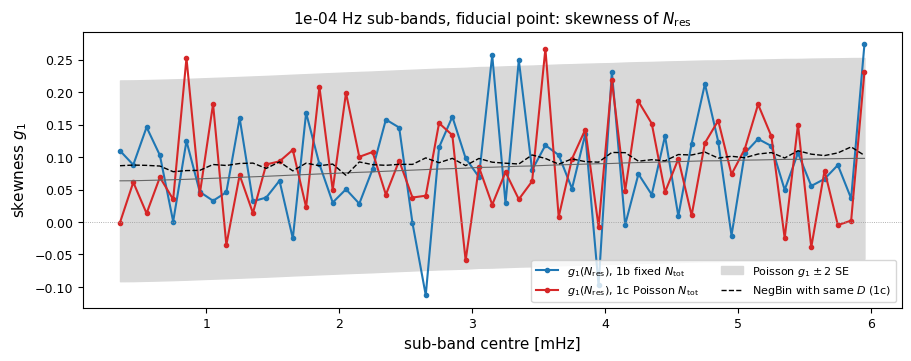

In [3]:
DATA_DIR = 'reviewer-response-data'
SUBBAND_WIDTH = 1e-4   ## [Hz], as in Studies 1b and 1c


sym_rng = np.random.default_rng(14)
rows = {}
with np.load(os.path.join(DATA_DIR, 'poisson_counts.npz')) as f:
    for p in f['point_names']:
        rows[f'Study 1, {p}'] = skew_summary(f[f'{p}__N_res'], sym_rng)
sym_data = {'1b fixed N_tot': load_fullband(os.path.join(DATA_DIR, 'poisson_counts_fullband.npz'), SUBBAND_WIDTH),
            '1c Poisson N_tot': load_fullband(os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot.npz'), SUBBAND_WIDTH)}
for name, d in sym_data.items():
    rows[f'{name}, full band'] = skew_summary(d['full']['N_res'], sym_rng)
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(rows).T)

## sub-bands: analytic standard error of g1 for n samples (normal-theory)
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
for (name, d), c in zip(sym_data.items(), ['C0', 'C3']):
    x = d['sub']['N_res']
    n = x.shape[0]
    se = np.sqrt(6*n*(n - 1)/((n - 2)*(n + 1)*(n + 3)))
    lam, D = x.mean(axis=0), x.var(axis=0, ddof=1)/x.mean(axis=0)
    g1 = ss.skew(x, axis=0, bias=False)
    g1_pois, g1_nb = 1/np.sqrt(lam), (2*D - 1)/np.sqrt(D*lam)
    z = (g1 - g1_pois)/se
    print(f"{name}: sub-band N_res skewness mean {g1.mean():.3f} (Poisson {g1_pois.mean():.3f}, NegBin(D) {g1_nb.mean():.3f}); "
          f"|g1 - g1_Poisson| > 2 SE in {np.sum(np.abs(z) > 2)} of {len(z)} (expected by chance: {0.0455*len(z):.1f}); "
          f"max |g1| = {np.abs(g1).max():.3f}; SE = {se:.3f}")
    ax.plot(d['sub_centres']*1e3, g1, 'o-', ms=3, color=c, label=rf"$g_1(N_\mathrm{{res}})$, {name.replace('N_tot', '$N_\\mathrm{tot}$')}")
ax.fill_between(d['sub_centres']*1e3, g1_pois - 2*se, g1_pois + 2*se, color='0.85', label=r'Poisson $g_1 \pm 2$ SE')
ax.plot(d['sub_centres']*1e3, g1_pois, color='0.4', lw=0.8)
ax.plot(d['sub_centres']*1e3, g1_nb, 'k--', lw=1, label=r'NegBin with same $D$ (1c)')
ax.axhline(0, color='0.6', lw=0.6, ls=':')
ax.set_xlabel('sub-band centre [mHz]', fontsize=11)
ax.set_ylabel(r'skewness $g_1$', fontsize=11)
ax.legend(fontsize=8, ncol=2)
ax.tick_params(labelsize=9)
ax.set_title(rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point: skewness of $N_\mathrm{{res}}$", fontsize=11)
fig.savefig(os.path.join(DATA_DIR, 'poisson_counts_nres_skewness.png'), dpi=150)
plt.show()

### Interpretation (symmetry)

**The overdispersed $N_\mathrm{res}$ distributions are symmetric to within the precision of 1000 realizations.
Their slight right skew is the size a Poisson distribution has anyway.**

- **Band totals.** Every bootstrap 95% interval on $g_1$ contains the Poisson value $1/\sqrt\lambda$.
  - Study 1 (narrow band): $g_1$ = 0.05, 0.15 and 0.11, against Poisson about 0.065.
  - Full band (1b, 1c): $g_1$ = −0.06 and −0.01, against Poisson 0.011.
- **Sub-bands.** The mean $g_1$ is 0.085 in both 1b and 1c, against Poisson 0.083 and a moment-matched
  negative binomial 0.094. Only 5 (1b) and 2 (1c) of 57 sub-bands differ from the Poisson skewness by more
  than 2 SE, against 2.6 expected by chance.
- **Sensitivity.** With SE($g_1$) ≈ 0.077, any asymmetry beyond about 0.15 in skewness is excluded. The Poisson
  and negative-binomial skewness differ by only about 0.01–0.02, which is too little to tell apart here.

**The mean is not affected by assuming Poisson statistics.**
- The Poisson MLE $\hat\lambda$ is the sample mean whatever the true distribution, so the fitted mean is unbiased.
- A skewed distribution would still leave the centre misplaced, with the median and mode away from where
  $\mathrm{Poisson}(\hat\lambda)$ puts them. That does not happen:
  - mean − median agrees with the Poisson value in every case, within its bootstrap interval;
  - it is at most 0.9 counts in Study 1, where the standard deviation is about 16;
  - it is at most 1.7 counts over the full band, where the standard deviation is about 100.

**Conclusion.** Assuming Poisson statistics gets the location right; overdispersion only makes it understate
the spread. A Poisson model of $N_\mathrm{res}$ underestimates the standard deviation by about
$\sqrt{D} - 1$: up to about 15% in these tests (D up to 1.32), and about 0–10% at high frequency. It does not
bias the mean.

# Study 1d: Poisson $N_\mathrm{tot}$, full toy-model band, fiducial point, 10,000 realizations

This is Study 1c with ten times as many realizations. Everything else is unchanged:
- $N_\mathrm{tot} \sim \mathrm{Poisson}(\lambda_\mathrm{tot} = 10^7)$, drawn independently for each realization;
- the toy grid (0.3–6 mHz, $\Delta f = 5\times10^{-5}$ Hz), the fiducial point and $\rho_\mathrm{thresh} = 7$;
- the per-bin thresholding (`count_per_bin`);
- the statistics, on the full band and on $10^{-4}$ Hz sub-bands.

New seeds make the draws independent of Study 1c.

**What the larger sample adds:**
- $\sigma_D$ falls from $\sqrt{2/999} \approx 0.045$ to $\sqrt{2/9999} \approx 0.014$.
- For the full-band $N_\mathrm{unres}$, the thinning diagnostic predicts $D \approx 1.009$, which is now about
  $0.6\,\sigma_D$ from 1.
- The standard error of the skewness falls from 0.077 to 0.024 per sub-band. Averaged over the 57 sub-bands, it
  is about 0.003. That should separate the Poisson and negative-binomial skewness, which differ by about 0.01.
- The binned KL test gains power.

**Run time:** at about 0.19 s per realization, roughly 32 min on the RTX 4070 laptop GPU.

**Before simulating:** run the Study 1b setup cell and its `count_per_bin` cell. Do not run 1b's pilot or
full run.

## Simulation (Poisson $N_\mathrm{tot}$, 10,000 realizations)

In [5]:
NREAL_1D = 10000         ## ten times Studies 1b and 1c
LAMBDA_TOT = int(1e7)    ## Poisson rate of the total number of binaries per galaxy, as in Study 1c
FD_SEED = 20261127       ## galaxy draws for this study
FD_NTOT_SEED = 20261128  ## N_tot draws
FD_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot_10k.npz')

## N_tot ~ Poisson(lambda_tot), one per realization
fd_ntot = np.random.default_rng(FD_NTOT_SEED).poisson(LAMBDA_TOT, size=NREAL_1D)
print(f"N_tot: mean {fd_ntot.mean():.1f}, var/mean {fd_ntot.var(ddof=1)/fd_ntot.mean():.3f}, "
      f"range {fd_ntot.min()}-{fd_ntot.max()}")

fd_rng = xp.random.default_rng(FD_SEED)
fd_popmodel = PopModel(LAMBDA_TOT, fd_rng, hyperprior=PopulationHyperPrior(fd_rng), fbins=fb_fbins, Nreal=1,
                       threshold_val=SNR_THRESH)

fd_nres = np.empty((NREAL_1D, NB), dtype=np.int64)
fd_nin = np.empty((NREAL_1D, NB), dtype=np.int64)
t0 = time.time()
## sparse progress updates keep the saved notebook small
for i in tqdm(range(NREAL_1D), mininterval=60):
    ## count_per_bin draws popmodel.N binaries, so set it to this realization's N_tot
    fd_popmodel.N = int(fd_ntot[i])
    fd_nres[i], fd_nin[i] = count_per_bin(fd_popmodel, FIDUCIAL)
print(f"{(time.time() - t0)/NREAL_1D:.2f} s per realization")
assert np.all(fd_nin >= fd_nres)

N_tot: mean 9999996.3, var/mean 1.000, range 9987838-10011292


  0%|          | 0/10000 [00:00<?, ?it/s]

  3%|▎         | 312/10000 [01:00<31:03,  5.20it/s]

  3%|▎         | 312/10000 [01:20<31:03,  5.20it/s]

  6%|▌         | 620/10000 [02:00<30:20,  5.15it/s]

  6%|▌         | 620/10000 [02:20<30:20,  5.15it/s]

... (58 outputs left out)

 98%|█████████▊| 9798/10000 [32:03<00:39,  5.08it/s]

 98%|█████████▊| 9798/10000 [32:20<00:39,  5.08it/s]

100%|██████████| 10000/10000 [32:42<00:00,  5.09it/s]

0.20 s per realization


In [6]:
## flat npz (no pickles), same keys as Study 1c
np.savez(FD_DATA_FILE,
         N_res_f=fd_nres, N_in_f=fd_nin, fbins=to_numpy(fb_fbins),
         hpar_names=np.array(list(FIDUCIAL)), theta=np.array(list(FIDUCIAL.values())),
         ntot=fd_ntot, lambda_tot=LAMBDA_TOT, nreal=NREAL_1D, snr_thresh=SNR_THRESH, sim_seed=FD_SEED,
         ntot_seed=FD_NTOT_SEED, fmin=FMIN, fmax=FMAX, fbin=FBIN, backend=BACKEND)
print("saved", FD_DATA_FILE)

saved reviewer-response-data/poisson_counts_fullband_poissonNtot_10k.npz


## Load data (Poisson $N_\mathrm{tot}$, 10,000 realizations)

**Restart point.** Run the two helper cells at the top first. The comparison below also loads the Study 1c file.

In [4]:
DATA_DIR = 'reviewer-response-data'
FD_DATA_FILE = os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot_10k.npz')
SUBBAND_WIDTH = 1e-4   ## [Hz], the width of the Study 1 band

fd_data = load_fullband(FD_DATA_FILE, SUBBAND_WIDTH)
m = fd_data['meta']
print(f"{fd_data['nreal']} realizations x {m['N_res_f'].shape[1]} bins of {m['fbin']:.0e} Hz on "
      f"[{m['fmin']*1e3:.2f}, {m['fmax']*1e3:.2f}) mHz; N_tot ~ Poisson({int(m['lambda_tot']):.0e}) "
      f"(sample mean {m['ntot'].mean():.1f}, D = {m['ntot'].var(ddof=1)/m['ntot'].mean():.3f}); "
      f"theta = {dict(zip(m['hpar_names'].tolist(), m['theta'].tolist()))}")
print(f"{fd_data['n_sub']} sub-bands of {SUBBAND_WIDTH:.0e} Hz")

10000 realizations x 114 bins of 5e-05 Hz on [0.30, 6.00) mHz; N_tot ~ Poisson(1e+07) (sample mean 9999996.3, D = 1.000); theta = {'m_mu': 0.6, 'm_sigma': 0.15, 'rh_disk': 3.31, 'r_bulge': 0.75, 'q_bd': 0.33, 'a_alpha': 0.5}
57 sub-bands of 1e-04 Hz


## Statistics (Poisson $N_\mathrm{tot}$, 10,000 realizations)

The same tests as Studies 1b and 1c are used. The KL null still has 1000 bootstrap replicates, each of 10,000
samples, so $p_\mathrm{KL}$ resolves down to 0.001. $D_\mathrm{ref}(N_\mathrm{in}) = 1$ everywhere.

In [5]:
fd_results, fd_summary = fullband_poisson_summary(fd_data, np.random.default_rng(15))
pd.options.display.float_format = '{:.4g}'.format
fd_summary.loc['full band']

   N_res: 57 sub-bands; median D = 1.075 (range 1.039-1.282); p_D < 0.05 in 57, p_KL < 0.05 in 46 (expected by chance: 2.9)
 N_unres: 57 sub-bands; median D = 1.033 (range 0.990-1.120); p_D < 0.05 in 32, p_KL < 0.05 in 20 (expected by chance: 2.9)


,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
quantity,,,,,,,,,
N_res,8796,9882,1.123,0,0.00495,0.001367,0.002069,0,1
N_unres,2.156e+06,2.145e+06,0.9947,0.7132,0.001719,0.001392,0.002055,0.202,1


In [6]:
fd_summary.drop('full band', level='band')

,,lambda_hat,sample var,D = var/mean,p_D,D_KL [nats],null median,null 95%,p_KL,D_ref(N_in)
band,quantity,,,,,,,,,
0.3-0.4 mHz,N_res,247.9,317.2,1.28,0,0.01774,0.001231,0.001993,0,1
0.4-0.5 mHz,N_res,246.5,316.1,1.282,0,0.01814,0.001241,0.00194,0,1
0.5-0.6 mHz,N_res,243.5,306.8,1.26,0,0.01594,0.00126,0.001892,0,1
0.6-0.7 mHz,N_res,240,297.5,1.24,0,0.01343,0.001255,0.001998,0,1
0.7-0.8 mHz,N_res,235.2,293.6,1.248,0,0.01385,0.00128,0.001997,0,1
...,...,...,...,...,...,...,...,...,...,...
5.5-5.6 mHz,N_unres,1952,2112,1.082,1.703e-08,0.003577,0.001349,0.002085,0,1
5.6-5.7 mHz,N_unres,1878,2068,1.101,4.311e-12,0.003383,0.001334,0.001974,0,1
5.7-5.8 mHz,N_unres,1807,1962,1.086,3.67e-09,0.003488,0.00134,0.001972,0,1


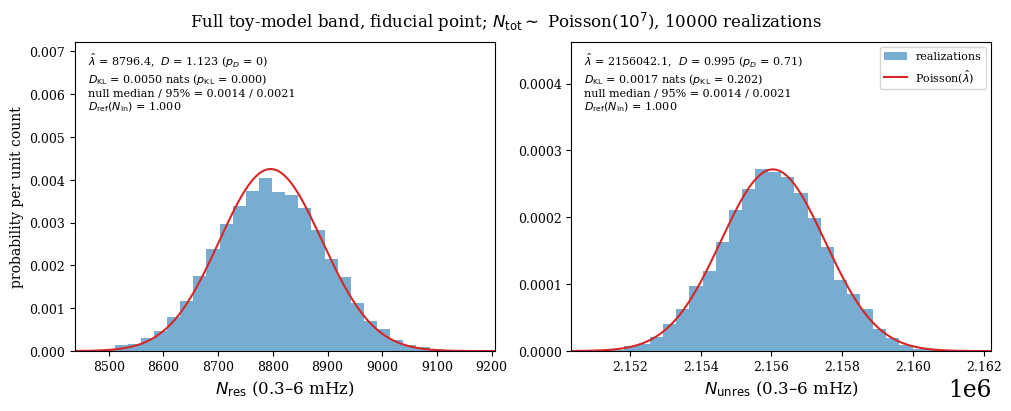

In [10]:
plot_fullband_hist(fd_data, fd_results,
                   rf"Full toy-model band, fiducial point; $N_\mathrm{{tot}} \sim$ Poisson($10^{{{np.log10(fd_data['meta']['lambda_tot']):.0f}}}$), "
                   rf"{fd_data['nreal']} realizations",
                   os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot_10k_hist.png'))
plt.show()

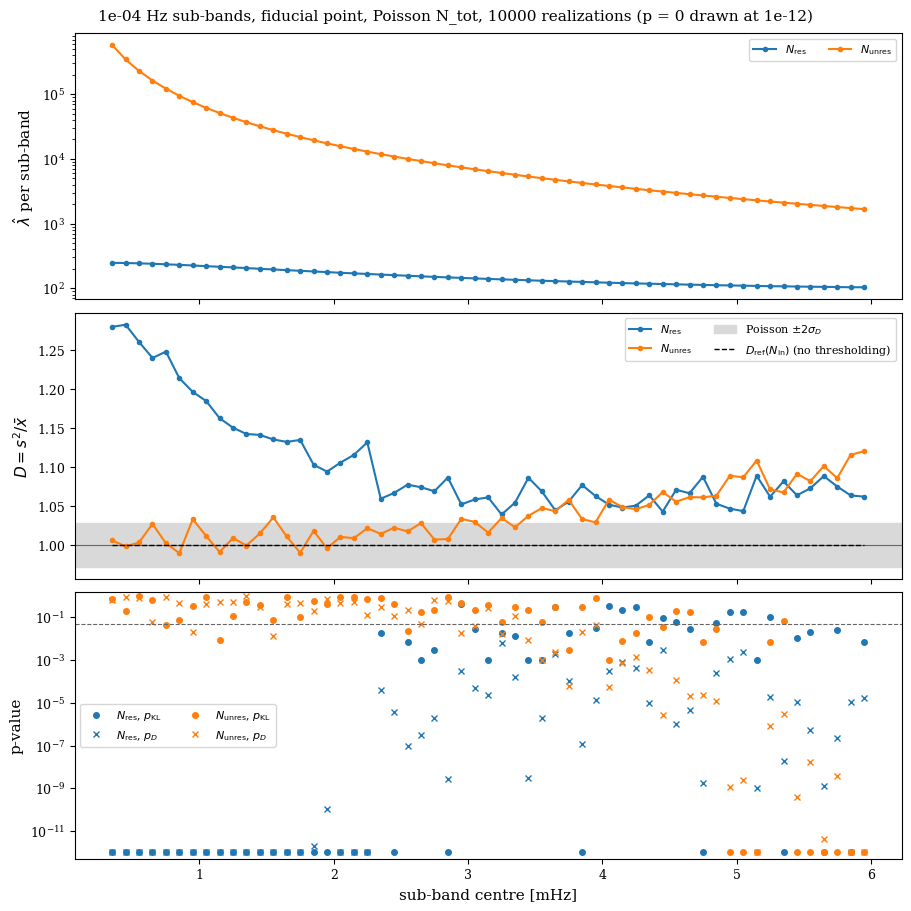

In [11]:
plot_subband_diagnostics(fd_data, fd_summary,
                         rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson N_tot, {fd_data['nreal']} realizations",
                         os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_10k_subbands.png'))
plt.show()

mean corr(N_res, N_in) over sub-bands: 0.031 (independent thinning: 0.141; 1-sigma noise per sub-band ~0.010)
mean D(N_in) over sub-bands: 0.999; full-band D(N_in) = 0.988 vs no-thresholding reference 1.000
mean correlation of N_res between different sub-bands: 0.0001


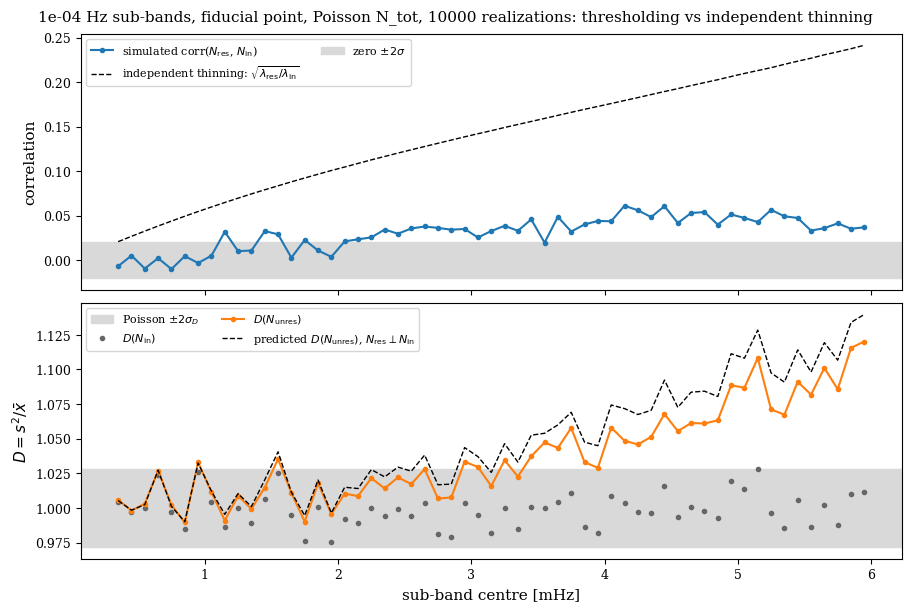

In [12]:
fd_diag = thinning_diagnostic(fd_data, rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson N_tot, "
                                       rf"{fd_data['nreal']} realizations: thresholding vs independent thinning",
                              os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_10k_thinning_diagnostic.png'))
plt.show()

### Comparison with Study 1c (1000 realizations)

The table gives the full-band dispersion indices of both studies with their $\sigma_D$. The column
$D_\perp(N_\mathrm{unres})$ is the thinning-diagnostic prediction from the full-band counts,
$(\lambda_\mathrm{in} D_\mathrm{in} + \lambda_\mathrm{res} D_\mathrm{res})/\lambda_\mathrm{unres}$, which assumes
$N_\mathrm{res}$ is uncorrelated with $N_\mathrm{in}$. The figure shows the sub-band $D$ of both studies, each
with its own Poisson $\pm 2\sigma_D$ band.

,sigma_D,D(N_in),p_D(N_in),D(N_res),p_D(N_res),D(N_unres),p_D(N_unres),D_perp(N_unres)
study,,,,,,,,
"Poisson N_tot, 1000 (1c)",0.04474,0.9782,0.6342,1.219,4.31e-06,0.9867,0.7766,0.9872
"Poisson N_tot, 10000 (1d)",0.01414,0.9876,0.3809,1.123,0,0.9947,0.7132,0.9962


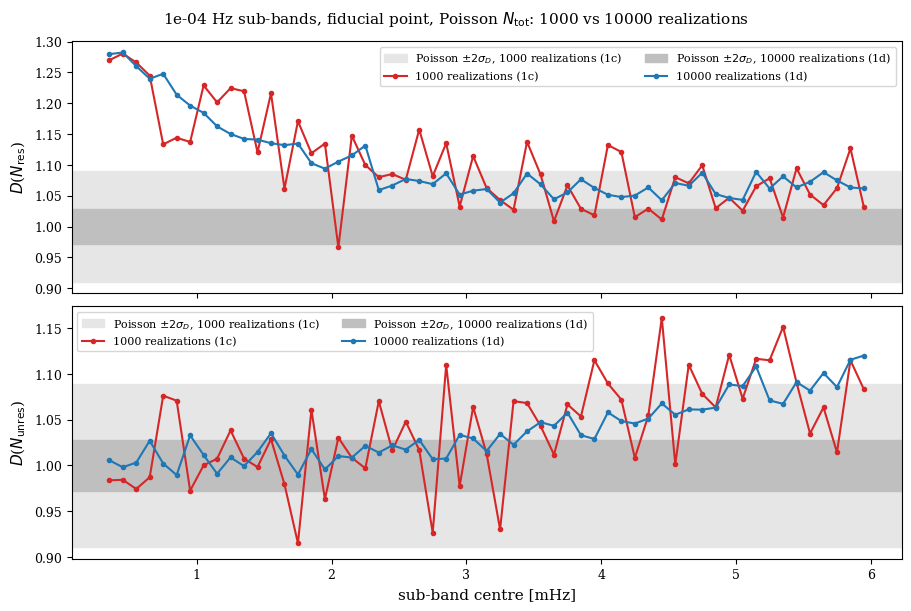

In [13]:
fc_cmp = load_fullband(os.path.join(DATA_DIR, 'poisson_counts_fullband_poissonNtot.npz'), SUBBAND_WIDTH)
rows = []
for label, d in [('Poisson N_tot, 1000 (1c)', fc_cmp), ('Poisson N_tot, 10000 (1d)', fd_data)]:
    row = {'study': label, 'sigma_D': np.sqrt(2/(d['nreal'] - 1))}
    lam, D = {}, {}
    for q in ['N_in', 'N_res', 'N_unres']:
        lam[q] = d['full'][q].mean()
        D[q], row[f'p_D({q})'] = dispersion_index(d['full'][q])
        row[f'D({q})'] = D[q]
    row['D_perp(N_unres)'] = (lam['N_in']*D['N_in'] + lam['N_res']*D['N_res'])/lam['N_unres']
    rows.append(row)
cols = ['sigma_D', 'D(N_in)', 'p_D(N_in)', 'D(N_res)', 'p_D(N_res)', 'D(N_unres)', 'p_D(N_unres)', 'D_perp(N_unres)']
display(pd.DataFrame(rows).set_index('study')[cols])

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, constrained_layout=True)
for ax, q in zip(axes, ['N_res', 'N_unres']):
    for label, d, c, shade in [('1000 realizations (1c)', fc_cmp, 'C3', '0.9'), ('10000 realizations (1d)', fd_data, 'C0', '0.75')]:
        sigma_D = np.sqrt(2/(d['nreal'] - 1))
        ax.axhspan(1 - 2*sigma_D, 1 + 2*sigma_D, color=shade, label=rf'Poisson $\pm 2\sigma_D$, {label}')
        x = d['sub'][q]
        ax.plot(d['sub_centres']*1e3, x.var(axis=0, ddof=1)/x.mean(axis=0), 'o-', ms=3, color=c, label=label)
    ax.set_ylabel(rf"$D$({FB_LABELS[q]})", fontsize=11)
    ax.legend(fontsize=8, ncol=2)
    ax.tick_params(labelsize=9)
axes[1].set_xlabel('sub-band centre [mHz]', fontsize=11)
fig.suptitle(rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson $N_\mathrm{{tot}}$: 1000 vs 10000 realizations", fontsize=11)
fig.savefig(os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_1k_vs_10k.png'), dpi=150)
plt.show()

### Symmetry of $N_\mathrm{res}$ (10,000 realizations)

This repeats the symmetry check for the full band and the sub-bands, using `skew_summary` from the helper cell.
With 10,000 realizations, the skewness averaged over sub-bands can be compared with both the Poisson value
$1/\sqrt\lambda$ and the moment-matched negative binomial $(2D - 1)/\sqrt{D\lambda}$. Its standard error is
$\mathrm{SE}(g_1)/\sqrt{n_\mathrm{sub}}$, which treats the sub-bands as independent (see the inter-sub-band
correlation printed by the thinning diagnostic).

,mean,D,g1,g1 2.5%,g1 97.5%,g1 Poisson,g1 NegBin(D),mean-median,mean-median 2.5%,mean-median 97.5%,mean-median Poisson
"1c (1000), full band",8.8e+03,1.22,-0.00577,-0.161,0.144,0.0107,0.0139,1.73,-4.75,5.34,-0.267
"1d (10000), full band",8.8e+03,1.12,0.0164,-0.0298,0.0646,0.0107,0.0125,1.41,-0.486,2.54,0.413


1c (1000): SE(g1) = 0.0773 per sub-band; mean over 57 sub-bands: g1 = 0.0852, Poisson 0.0829, NegBin(D) 0.0941
    mean(g1 - g1_Poisson) = +0.0023 +- 0.0102 (+0.2 SE); mean(g1 - g1_NegBin) = -0.0089 +- 0.0102 (-0.9 SE); |g1 - g1_Poisson| > 2 SE in 2 of 57 (expected by chance: 2.6)
1d (10000): SE(g1) = 0.0245 per sub-band; mean over 57 sub-bands: g1 = 0.0949, Poisson 0.0829, NegBin(D) 0.0941
    mean(g1 - g1_Poisson) = +0.0120 +- 0.0032 (+3.7 SE); mean(g1 - g1_NegBin) = +0.0007 +- 0.0032 (+0.2 SE); |g1 - g1_Poisson| > 2 SE in 4 of 57 (expected by chance: 2.6)


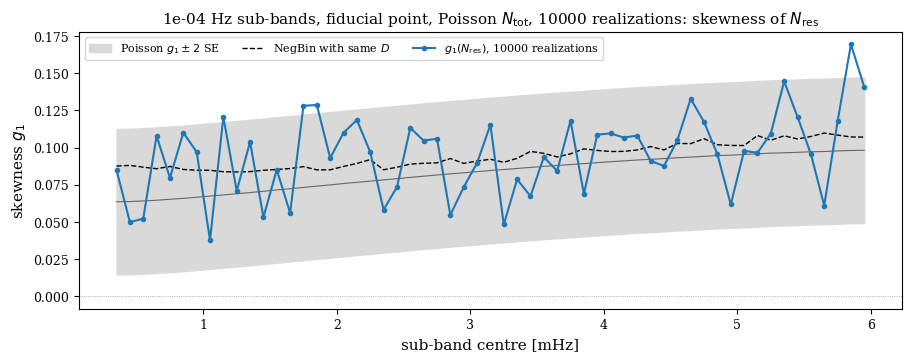

In [14]:
sym_rng_1d = np.random.default_rng(16)
rows = {f'{label}, full band': skew_summary(d['full']['N_res'], sym_rng_1d)
        for label, d in [('1c (1000)', fc_cmp), ('1d (10000)', fd_data)]}
pd.options.display.float_format = '{:.3g}'.format
display(pd.DataFrame(rows).T)

## sub-bands: analytic (normal-theory) standard error of g1 for n samples
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
for label, d in [('1c (1000)', fc_cmp), ('1d (10000)', fd_data)]:
    x = d['sub']['N_res']
    n, n_sub = x.shape
    se = np.sqrt(6*n*(n - 1)/((n - 2)*(n + 1)*(n + 3)))
    lam, D = x.mean(axis=0), x.var(axis=0, ddof=1)/x.mean(axis=0)
    g1 = ss.skew(x, axis=0, bias=False)
    g1_pois, g1_nb = 1/np.sqrt(lam), (2*D - 1)/np.sqrt(D*lam)
    se_mean = se/np.sqrt(n_sub)
    print(f"{label}: SE(g1) = {se:.4f} per sub-band; mean over {n_sub} sub-bands: g1 = {g1.mean():.4f}, "
          f"Poisson {g1_pois.mean():.4f}, NegBin(D) {g1_nb.mean():.4f}")
    print(f"    mean(g1 - g1_Poisson) = {np.mean(g1 - g1_pois):+.4f} +- {se_mean:.4f} ({np.mean(g1 - g1_pois)/se_mean:+.1f} SE); "
          f"mean(g1 - g1_NegBin) = {np.mean(g1 - g1_nb):+.4f} +- {se_mean:.4f} ({np.mean(g1 - g1_nb)/se_mean:+.1f} SE); "
          f"|g1 - g1_Poisson| > 2 SE in {np.sum(np.abs(g1 - g1_pois) > 2*se)} of {n_sub} (expected by chance: {0.0455*n_sub:.1f})")
## figure: Study 1d only (its last-loop values)
f_mHz = fd_data['sub_centres']*1e3
ax.fill_between(f_mHz, g1_pois - 2*se, g1_pois + 2*se, color='0.85', label=r'Poisson $g_1 \pm 2$ SE')
ax.plot(f_mHz, g1_pois, color='0.4', lw=0.8)
ax.plot(f_mHz, g1_nb, 'k--', lw=1, label=r'NegBin with same $D$')
ax.plot(f_mHz, g1, 'o-', ms=3, color='C0', label=r'$g_1(N_\mathrm{res})$, 10000 realizations')
ax.axhline(0, color='0.6', lw=0.6, ls=':')
ax.set_xlabel('sub-band centre [mHz]', fontsize=11)
ax.set_ylabel(r'skewness $g_1$', fontsize=11)
ax.legend(fontsize=8, ncol=3)
ax.tick_params(labelsize=9)
ax.set_title(rf"{SUBBAND_WIDTH:.0e} Hz sub-bands, fiducial point, Poisson $N_\mathrm{{tot}}$, 10000 realizations: "
             r"skewness of $N_\mathrm{res}$", fontsize=11)
fig.savefig(os.path.join(DATA_DIR, 'poisson_counts_poissonNtot_10k_nres_skewness.png'), dpi=150)
plt.show()

### Interpretation (10,000 realizations)

**Full band (0.3–6 mHz): Study 1c's conclusions hold at three times the precision** ($\sigma_D$ = 0.014).

| full band | 1c (1000) | 1d (10,000) |
|---|---|---|
| $D(N_\mathrm{in})$ | 0.978 ($p_D$ = 0.63) | 0.988 ($p_D$ = 0.38) |
| $D(N_\mathrm{unres})$ | 0.987 ($p_D$ = 0.78, $p_\mathrm{KL}$ = 0.17) | 0.995 ($p_D$ = 0.71, $p_\mathrm{KL}$ = 0.20) |
| $D(N_\mathrm{res})$ | 1.219 ($p_D = 4\times10^{-6}$, $p_\mathrm{KL}$ = 0.16) | 1.123 ($p_D$ = 0, $p_\mathrm{KL} < 0.001$) |

- **$N_\mathrm{unres}$ is consistent with Poisson.** Its $D$ is within $0.4\,\sigma_D$ of 1, and the binned KL is
  inside its null. The thinning prediction $D_\perp$ = 0.996 matches.
- **$N_\mathrm{res}$ is overdispersed, $D = 1.12$.** Both tests now reject Poisson decisively; the binned KL
  ($D_\mathrm{KL}$ = 0.0050 nats against a null 95th percentile of 0.0021) now has the power it lacked at 1000
  realizations. Study 1c's 1.22 was a high fluctuation: about $1.8\sigma$ from 1.12, using the overdispersed
  sampling error $\sigma_D \approx D\sqrt{2/(n-1)} \approx 0.05$ for $n = 1000$. Study 1b's 1.15 (fixed
  $N_\mathrm{tot}$) is consistent with it.

**Sub-bands ($10^{-4}$ Hz).** With $\sigma_D$ = 0.014 the frequency trends that were noisy in 1b and 1c are
now clear (see the 1000-vs-10,000 figure).
- **$N_\mathrm{res}$ is overdispersed in every sub-band**: $D$ ranges from 1.04 to 1.28, with a median of
  1.075. It falls smoothly from about 1.28 at 0.3–0.5 mHz to about 1.10 at 2 mHz, then stays at 1.04–1.09 above
  3 mHz. All 57 sub-bands have $p_D < 0.05$, and 46 have $p_\mathrm{KL} < 0.05$.
- **$N_\mathrm{unres}$ is close to Poisson below about 3 mHz** ($D$ = 0.99–1.035). Above that, $D$ rises
  smoothly to 1.12 at 6 mHz. 32 of 57 sub-bands have $p_D < 0.05$: 28 of the 30 above 3 mHz, and 4 of the 27 below it. The thinning
  diagnostic again explains this:
  - $N_\mathrm{res}$ is nearly uncorrelated with $N_\mathrm{in}$: mean correlation 0.031, against 0.141 for
    independent thinning.
  - $N_\mathrm{unres} = N_\mathrm{in} - N_\mathrm{res}$ therefore inherits the variance of $N_\mathrm{res}$.
    That matters only at high frequency, where $\lambda_\mathrm{res}/\lambda_\mathrm{unres}$ is largest.
- **$N_\mathrm{in}$** has a mean sub-band $D$ of 0.999.
- **Sub-bands are independent**: the mean correlation of $N_\mathrm{res}$ between different sub-bands is 0.0001.

**Symmetry: the skewness of $N_\mathrm{res}$ is now resolved, and it is negative-binomial-like.**
- **Sub-bands.** Averaged over the 57 sub-bands, $g_1$ = 0.095 ± 0.003. That is 0.012 above the Poisson value
  (3.7 SE) and equal to the moment-matched negative binomial (0.094, +0.2 SE). At 1000 realizations (1c) the
  same comparison could not separate the two (0.2 SE and −0.9 SE). Only 4 of 57 sub-bands lie beyond 2 SE of the
  Poisson value, so no single sub-band is strongly skewed.
- **Full band.** $g_1$ = 0.016 [−0.030, 0.065], consistent with both Poisson (0.011) and the negative binomial
  (0.013).
- **The location is still unaffected.** mean − median in the full band is 1.4 [−0.5, 2.5] counts, against 0.4 for
  Poisson, where the standard deviation is about 99. The excess sub-band skewness of 0.012 shifts the median
  relative to the mean by roughly $\Delta g_1\,\sigma/6 \approx 0.04$ counts, for $\sigma \approx 18$.

**Conclusion.** A Poisson model gets the mean of $N_\mathrm{res}$ right and its shape nearly right. Its only
material error is the variance, understated by a factor $D$ of 1.04–1.28, i.e. a standard deviation 2–13% too
small, worst at low frequency. A negative binomial with the measured $D$ reproduces both the variance and the
skewness. $N_\mathrm{unres}$ is Poisson across the full band, and in sub-bands below about 3 mHz; above that, it
inherits a few percent of excess variance from $N_\mathrm{res}$.

In [9]:
## pelargir (main branch) picks its array backend at import time
os.environ['PELARGIR_GPU'] = '1'
sys.path.insert(1, '../pelargir/')
from utils import set_style
set_style()

In [52]:
import matplotlib.ticker as mticker

In [53]:
class CompactSciFormatter(mticker.Formatter):
    '''

    Tick formatter that writes large values in compact scientific notation, e.g. 2.152e6, so each tick carries
    its own exponent instead of a separate "1e6" multiplier at the end of the axis. It uses the fewest mantissa
    decimals that reproduce every tick location, and the same number on every tick.

    Arguments
    ------------------------------
    sci_min : float
    	Ticks whose magnitude is below this value are written plainly with '{:g}'. (Default: 1e6)

    Returns
    ------------------------------
    None

    '''

    def __init__(self, sci_min=1e6):
        self.sci_min = sci_min

    def __call__(self, x, pos=None):
        '''

        Format one tick value.

        Arguments
        ------------------------------
        x : float
        	Tick value.
        pos : int or None
        	Tick position (unused; part of the matplotlib Formatter interface). (Default: None)

        Returns
        ------------------------------
        label : str
        	Tick label, e.g. '2.152e6', or the '{:g}' form below sci_min.

        '''
        if x == 0 or abs(x) < self.sci_min:
            return f"{x:g}"
        ## self.locs is set by the axis before labelling; fall back to this tick alone if it is empty
        locs = np.asarray(self.locs if len(self.locs) else [x], dtype=float)
        ## one exponent for the whole axis, taken from the largest tick
        exp = int(np.floor(np.log10(np.max(np.abs(locs)))))
        scale = 10.0**exp
        ## fewest decimals that reproduce every tick (handles 2.5-type steps, e.g. 2.1525e6)
        tol = 1e-6*np.min(np.diff(np.sort(locs))) if len(locs) > 1 else 1e-6*abs(x)
        for d in range(10):
            if np.all(np.abs(np.round(locs/scale, d)*scale - locs) <= tol):
                break
        return f"{x/scale:.{d}f}e{exp}"

In [60]:
def make_new_manuscript_plot(data, results, outfile):
    '''

    Histograms of the full-band N_res and N_unres with the fitted Poisson pmf and the test statistics.

    Arguments
    ------------------------------
    data : dict
    	Output of load_fullband.
    results : dict
    	Output of fullband_poisson_summary.
    title : str
    	Figure title.
    outfile : str
    	PNG path to save to.

    Returns
    ------------------------------
    fig : matplotlib.figure.Figure
    	The figure.

    '''
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    f_lo, f_hi = data['meta']['fmin']*1e3, data['meta']['fmax']*1e3
    txts = [r"$p(\mathrm{Poisson}) < 0.0001$",r"$p(\mathrm{Poisson}) > 0.05$"]
    for ax, qname, txt in zip(axes, ['N_res', 'N_unres'], txts):
        r = results[('full band', qname)]
        x = data['full'][qname]
        lam, edges = r['lambda_hat'], r['_edges']
        width = edges[1] - edges[0]
        ## empirical density per unit count on the KL bins, against the fitted Poisson pmf
        h = ax.hist(x, bins=edges, density=True, color='teal', alpha=0.6, label='Realizations')[0]
        k = np.arange(int(np.floor(lam - 5*np.sqrt(lam))), int(np.ceil(lam + 5*np.sqrt(lam))) + 1)
        ax.plot(k, ss.poisson.pmf(k, lam), color='mediumorchid', lw=1.5, label=r'Poisson($\hat\lambda$)')
        ax.set_xlim(edges[0] - width, edges[-1] + width)
        ## headroom above the histogram for the statistics annotation
        ax.set_ylim(0, 1.3*max(h.max(), ss.poisson.pmf(np.round(lam), lam)))
        ax.set_xlabel(FB_LABELS[qname] + f' ({f_lo:.1f}–{f_hi:.0f} mHz)', fontsize=14)
        ax.set_yticks([])
        ax.tick_params(labelsize=12)
        ax.xaxis.set_major_formatter(CompactSciFormatter())
        # txt = r"$p(\mathrm{Poisson}$"+rf" = {r['p_D']:.2g})"
        # txt = (rf"$\hat\lambda$ = {lam:.1f},  $D$ = {r['D = var/mean']:.3f} ($p_D$ = {r['p_D']:.2g})" + '\n'
        #        + rf"$D_\mathrm{{KL}}$ = {r['D_KL [nats]']:.4f} nats ($p_\mathrm{{KL}}$ = {r['p_KL']:.3f})" + '\n'
        #        + rf"null median / 95% = {r['null median']:.4f} / {r['null 95%']:.4f}" + '\n'
        #        + rf"$D_\mathrm{{ref}}(N_\mathrm{{in}})$ = {r['D_ref(N_in)']:.3f}")
        ax.text(0.03, 0.97, txt, transform=ax.transAxes, va='top', ha='left', fontsize=14)
    axes[0].set_ylabel('$p(N)$',fontsize=14)
    axes[1].legend(loc='upper right', fontsize=14)
    # fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    fig.savefig(outfile, dpi=150)
    return fig

/tmp/ipykernel_42833/734882971.py:51: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


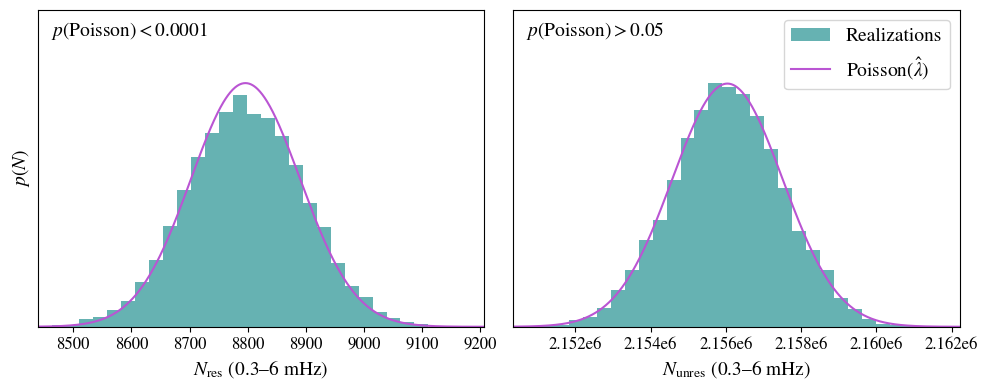

In [61]:
make_new_manuscript_plot(fd_data,
                   fd_results,
                   os.path.join(DATA_DIR, 'check_poisson_statistics.png'))
plt.show()

/tmp/ipykernel_42833/734882971.py:51: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


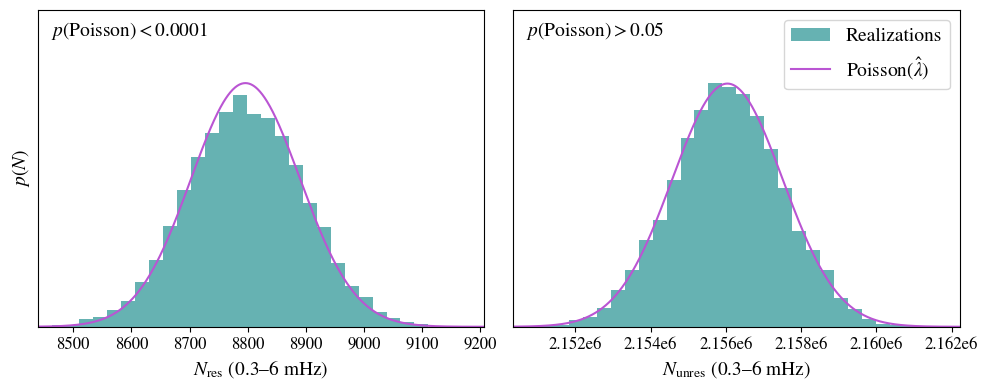

In [62]:
make_new_manuscript_plot(fd_data,
                   fd_results,
                   os.path.join(DATA_DIR, 'check_poisson_statistics.pdf'))
plt.show()